# Machine Learning Pipeline
**IT3091 Machine Learning: European Football Match Outcome Prediction Using Team Form, Starting-XI Positional Strength and Tactical Context**

This notebook implements the Machine Learning stage on the **final engineered** dataset. It does not rebuild the Stage 1 / Stage 2 feature engineering.

| Item | Value |
|---|---|
| Task | Three-class classification: **H** (home win), **D** (draw), **A** (away win) |
| Unit of analysis | One football match |
| Primary metric | **Macro-F1** (Draw is the minority class) |
| Secondary diagnostics | Log Loss, multiclass Brier score, class-wise precision / recall / F1 |
| Split | Chronological: train `season_start <= 2022`, validation `== 2023`, test `>= 2024` |
| Random seed | `RANDOM_STATE = 42` |

## 1. Project Objective

**RQ1.** Can recent team form, starting-XI player strength, squad composition, positional strengths and league context be used to predict European football match outcomes before kickoff?

**RQ2.** Does adding player-aware and positional information improve predictive performance compared with team-level form and match context alone?

RQ2 is answered with the cumulative **FS1 to FS4 ablation** (Section 12). The claims made at the end of the notebook are generated from the numbers the notebook actually computes.

## 2. Prediction Boundary

The prediction is made **after the official starting XI is known and before kickoff**. Only information that exists at that moment may enter `X`: prior-match form, the announced XI and formation, pre-match player strength values, and league context.

Never allowed in `X`: final goals (`audit_home_goals`, `audit_away_goals`), `target_result`, and any in-match statistic or event (shots, possession, corners, cards, fouls, substitutions, appearances). Bookmaker odds are not part of this primary model.

In [1]:
# ---- Imports and reproducibility header -------------------------------------------------
import os, sys, platform, time, warnings, joblib
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, log_loss,
                             precision_recall_fscore_support, confusion_matrix)

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_FILE = "European_Football_PlayerAware_Primary_9Leagues_2008_2026.csv"
OUT_DIR = "ml_outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

CLASSES = ["H", "D", "A"]            # fixed reporting order: Home, Draw, Away
CLASS_NAMES = {"H": "Home", "D": "Draw", "A": "Away"}

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 12,
                     "axes.labelsize": 10, "legend.fontsize": 9})

print("Python       :", sys.version.split()[0])
print("Platform     :", platform.platform())
print("pandas       :", pd.__version__)
print("numpy        :", np.__version__)
print("scikit-learn :", sklearn.__version__)
print("matplotlib   :", matplotlib.__version__)
print("RANDOM_STATE :", RANDOM_STATE)

Python       : 3.12.3
Platform     : Linux-6.18.44-fc-v50-x86_64-with-glibc2.39
pandas       : 3.0.2
numpy        : 2.4.4
scikit-learn : 1.8.0
matplotlib   : 3.10.8
RANDOM_STATE : 42


## 3. Dataset Loading

The CSV is read as-is. The notebook never writes back to it.

In [2]:
# ---- Locate and load the final engineered CSV (read-only) -------------------------------
candidates = [DATA_FILE, os.path.join("data", DATA_FILE), os.path.join("..", DATA_FILE)]
DATA_PATH = next((p for p in candidates if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"Could not find {DATA_FILE}. Put it next to this notebook (or in ./data/).")

df_raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
print("Dataset file :", DATA_PATH)
print("Shape        :", df_raw.shape)
display(df_raw.head())

Dataset file : European_Football_PlayerAware_Primary_9Leagues_2008_2026.csv
Shape        : (51201, 62)


,match_uid,data_source,strength_method,game_id,date,season_start,season,league_code,league_name,country,...,away_lineup_continuity,xi_strength_diff,home_attack_vs_away_defence,away_attack_vs_home_defence,midfield_strength_diff,gk_strength_diff,player_feature_ready,audit_home_goals,audit_away_goals,target_result
0,S1_483129,european_soccer_sqlite_stage1,fifa_overall_rating_causal_prior_league_role_p...,483129,2008-08-09,2008,2008/2009,FR1,France Ligue 1,France,...,NaN,NaN,NaN,NaN,NaN,NaN,0,2,1,H
1,S1_483130,european_soccer_sqlite_stage1,fifa_overall_rating_causal_prior_league_role_p...,483130,2008-08-09,2008,2008/2009,FR1,France Ligue 1,France,...,NaN,NaN,NaN,NaN,NaN,NaN,0,2,1,H
2,S1_483131,european_soccer_sqlite_stage1,fifa_overall_rating_causal_prior_league_role_p...,483131,2008-08-09,2008,2008/2009,FR1,France Ligue 1,France,...,NaN,NaN,NaN,NaN,NaN,NaN,0,1,0,H
3,S1_483132,european_soccer_sqlite_stage1,fifa_overall_rating_causal_prior_league_role_p...,483132,2008-08-09,2008,2008/2009,FR1,France Ligue 1,France,...,NaN,NaN,NaN,NaN,NaN,NaN,0,0,1,A
4,S1_483134,european_soccer_sqlite_stage1,fifa_overall_rating_causal_prior_league_role_p...,483134,2008-08-09,2008,2008/2009,FR1,France Ligue 1,France,...,NaN,NaN,NaN,NaN,NaN,NaN,0,1,0,H


## 4. Dataset QA

Checks: shape, data types, missing values, duplicate `match_uid`, target distribution, date range and league distribution. The "reference" values are the approximate figures given in the project brief; they are compared with, not forced onto, the actual file.

In [3]:
# ---- Data types and missing values -------------------------------------------------------
dtype_table = pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "n_missing": df_raw.isna().sum(),
                            "pct_missing": (df_raw.isna().mean() * 100).round(2)})
display(dtype_table)

# ---- Core QA facts ------------------------------------------------------------------------
n_dup_uid = int(df_raw["match_uid"].duplicated().sum())
target_counts = df_raw["target_result"].value_counts().reindex(CLASSES)
print("Duplicate match_uid values:", n_dup_uid)
print("\nTarget distribution:")
display(pd.DataFrame({"count": target_counts, "share_%": (target_counts / len(df_raw) * 100).round(2)}))
print("Date range:", df_raw["date"].min().date(), "to", df_raw["date"].max().date())
print("\nLeague distribution:")
display(df_raw["league_code"].value_counts().rename("matches").to_frame())

# ---- Dataset QA table (actual vs. approximate reference from the brief) -------------------
qa = pd.DataFrame([
    ["Rows", len(df_raw), 51201],
    ["Columns", df_raw.shape[1], None],
    ["Distinct leagues", df_raw["league_code"].nunique(), 9],
    ["Duplicate match_uid", n_dup_uid, 0],
    ["Target H", int(target_counts["H"]), 23020],
    ["Target D", int(target_counts["D"]), 12773],
    ["Target A", int(target_counts["A"]), 15408],
    ["Earliest date", str(df_raw["date"].min().date()), "2008-08-09"],
    ["Latest date", str(df_raw["date"].max().date()), "2026-05-24"],
], columns=["check", "actual", "reference_from_brief"])
qa["matches_reference"] = [("n/a" if r is None else str(a) == str(r)) for a, r in zip(qa["actual"], qa["reference_from_brief"])]
display(qa)

,dtype,n_missing,pct_missing
match_uid,str,0,0.0
data_source,str,0,0.0
strength_method,str,0,0.0
game_id,int64,0,0.0
date,datetime64[us],0,0.0
...,...,...,...
gk_strength_diff,float64,1384,2.7
player_feature_ready,int64,0,0.0
audit_home_goals,int64,0,0.0
audit_away_goals,int64,0,0.0


Duplicate match_uid values: 0

Target distribution:


,count,share_%
target_result,,
H,23020,44.96
D,12773,24.95
A,15408,30.09


Date range: 2008-08-09 to 2026-05-24

League distribution:


,matches
league_code,
GB1,6840
ES1,6840
IT1,6817
FR1,6517
L1,5508
NL1,5434
PO1,5112
BE1,4318
SC1,3815


,check,actual,reference_from_brief,matches_reference
0,Rows,51201,51201,True
1,Columns,62,None,n/a
2,Distinct leagues,9,9,True
3,Duplicate match_uid,0,0,True
4,Target H,23020,23020,True
5,Target D,12773,12773,True
6,Target A,15408,15408,True
7,Earliest date,2008-08-09,2008-08-09,True
8,Latest date,2026-05-24,2026-05-24,True


## 5. Leakage Audit

### 5.1 Final ML data audit
Targets, dates and ranges are validated before any modelling. Nothing is modified; problems would be reported, not silently fixed.

In [4]:
# ---- A/B/C: duplicates, target labels, dates ----------------------------------------------
audit_checks = []
audit_checks.append(("match_uid unique", n_dup_uid == 0))
audit_checks.append(("target_result only in {H, D, A}", set(df_raw["target_result"].dropna().unique()) <= set(CLASSES)))
audit_checks.append(("target_result has no missing values", df_raw["target_result"].notna().all()))
audit_checks.append(("date parsed, no missing dates", df_raw["date"].notna().all()))
audit_checks.append(("season_start has no missing values", df_raw["season_start"].notna().all()))

# Target must be consistent with the audit goals (audit columns are used ONLY for this check)
derived = np.where(df_raw["audit_home_goals"] > df_raw["audit_away_goals"], "H",
          np.where(df_raw["audit_home_goals"] == df_raw["audit_away_goals"], "D", "A"))
n_target_mismatch = int((derived != df_raw["target_result"].to_numpy()).sum())
audit_checks.append((f"target_result agrees with audit goals (mismatches = {n_target_mismatch})", n_target_mismatch == 0))
display(pd.DataFrame(audit_checks, columns=["check", "passed"]))

# ---- E: feature range checks --------------------------------------------------------------
strength_cols = [c for c in df_raw.columns if any(k in c for k in ["xi_strength", "attack_strength", "midfield_strength",
                 "defence_strength", "gk_strength", "top3_strength"]) and "diff" not in c and "_vs_" not in c]
range_rows = []
for c in strength_cols:
    s = df_raw[c]
    range_rows.append([c, s.min(), s.max(), int(((s < 0) | (s > 100)).sum())])
for c in [c for c in df_raw.columns if c.endswith("coverage") or c.endswith("lineup_continuity") or c.endswith("win_rate_L5")]:
    s = df_raw[c]
    range_rows.append([c, s.min(), s.max(), int(((s < 0) | (s > 1)).sum())])
for c in [c for c in df_raw.columns if c.endswith("form_n_L5")]:
    s = df_raw[c]
    range_rows.append([c, s.min(), s.max(), int(((s < 0) | (s > 5)).sum())])
range_table = pd.DataFrame(range_rows, columns=["column", "min", "max", "n_out_of_expected_range"])
print("Strength columns are expected in [0, 100]; coverage, continuity and win rate in [0, 1]; form_n in [0, 5].")
display(range_table)

,check,passed
0,match_uid unique,True
1,"target_result only in {H, D, A}",True
2,target_result has no missing values,True
3,"date parsed, no missing dates",True
4,season_start has no missing values,True
5,target_result agrees with audit goals (mismatc...,True


Strength columns are expected in [0, 100]; coverage, continuity and win rate in [0, 1]; form_n in [0, 5].


,column,min,max,n_out_of_expected_range
0,home_xi_strength,3.7952,99.6539,0
1,away_xi_strength,3.8409,99.6809,0
2,home_attack_strength,0.0000,100.0000,0
3,away_attack_strength,0.0000,100.0000,0
4,home_midfield_strength,0.3336,99.9080,0
5,away_midfield_strength,0.0904,99.8841,0
6,home_defence_strength,0.4715,99.9803,0
7,away_defence_strength,1.9868,100.0000,0
8,home_gk_strength,0.0000,100.0000,0
9,away_gk_strength,0.0000,100.0000,0


### 5.2 Column-level leakage audit table
Every one of the dataset's columns receives an explicit role, reason and action. `KEEP` means the column belongs to an approved feature set (Section 8).

In [5]:
# ---- Feature sets are defined first, because the audit table refers to them ---------------
FS1_COLS = ["home_form_n_L5", "away_form_n_L5", "home_points_per_game_L5", "away_points_per_game_L5",
            "home_win_rate_L5", "away_win_rate_L5", "home_goals_for_avg_L5", "away_goals_for_avg_L5",
            "home_goals_against_avg_L5", "away_goals_against_avg_L5", "home_goal_diff_avg_L5",
            "away_goal_diff_avg_L5", "league_code"]
FS2_ADD = ["home_starter_count", "away_starter_count", "home_strength_known_n", "away_strength_known_n",
           "home_strength_coverage", "away_strength_coverage", "home_xi_strength", "away_xi_strength",
           "home_top3_strength", "away_top3_strength", "home_top3_gap", "away_top3_gap", "xi_strength_diff"]
FS3_ADD = ["home_attack_strength", "away_attack_strength", "home_midfield_strength", "away_midfield_strength",
           "home_defence_strength", "away_defence_strength", "home_gk_strength", "away_gk_strength",
           "home_attack_vs_away_defence", "away_attack_vs_home_defence", "midfield_strength_diff", "gk_strength_diff"]
FS4_ADD = ["home_formation", "away_formation", "home_lineup_continuity", "away_lineup_continuity"]

FEATURE_SETS = {"FS1": FS1_COLS,
                "FS2": FS1_COLS + FS2_ADD,
                "FS3": FS1_COLS + FS2_ADD + FS3_ADD,
                "FS4": FS1_COLS + FS2_ADD + FS3_ADD + FS4_ADD}
FS_ORDER = ["FS1", "FS2", "FS3", "FS4"]
CATEGORICAL = ["league_code", "home_formation", "away_formation"]
INTRODUCED_IN = {c: fs for fs, cols in [("FS1", FS1_COLS), ("FS2", FS2_ADD), ("FS3", FS3_ADD), ("FS4", FS4_ADD)] for c in cols}

# A requested feature that is absent must be REPORTED, not invented (requirement 11).
missing_requested = sorted({c for cols in FEATURE_SETS.values() for c in cols} - set(df_raw.columns))
print("Requested features absent from the CSV:", missing_requested if missing_requested else "none")
assert not missing_requested, "Stop: a requested feature is absent. Report it instead of creating fake data."

# ---- Audit table ---------------------------------------------------------------------------
approved = set(FEATURE_SETS["FS4"])
identifiers = {"match_uid", "game_id", "home_team_id", "away_team_id", "home_team", "away_team"}
def audit_row(col):
    if col in ("audit_home_goals", "audit_away_goals"):
        return ("final match information (defines the target)", "REMOVE")
    if col == "target_result":
        return ("target label", "REMOVE FROM X")
    if col in approved:
        return (f"pre-match feature (introduced in {INTRODUCED_IN[col]})", "KEEP")
    if col in identifiers:
        return ("identifier / label; memorisation risk, no football signal", "EXCLUDE FROM X")
    if col in ("date", "season_start", "season"):
        return ("used for chronological sorting and splitting only", "EXCLUDE FROM X")
    if col in ("data_source", "strength_method", "league_coverage_flag"):
        return ("provenance metadata, not part of the approved feature sets", "EXCLUDE FROM X")
    if col in ("league_name", "country"):
        return ("redundant with league_code; spelling differs by source", "EXCLUDE FROM X")
    if col in ("home_strength_age_mean_days", "away_strength_age_mean_days", "player_feature_ready"):
        return ("pre-match evidence-quality column; not in approved sets, kept for robustness slicing", "EXCLUDE FROM X")
    return ("not in approved feature sets", "EXCLUDE FROM X")

leak_audit = pd.DataFrame([(c, *audit_row(c)) for c in df_raw.columns], columns=["column", "reason", "action"])
display(leak_audit)
print(leak_audit["action"].value_counts().to_string())

# ---- Hard guards: these assertions stop the notebook if leakage ever enters X -------------
FORBIDDEN = {"audit_home_goals", "audit_away_goals", "target_result"}
assert not (approved & FORBIDDEN), "Leakage: forbidden column present in a feature set"
suspicious = ["audit", "target", "shot", "possess", "corner", "card", "foul", "event", "subst", "appearance", "odds", "b365"]
hits = [c for c in approved if any(k in c.lower() for k in suspicious)]
assert not hits, f"Suspicious column names in feature sets: {hits}"
print("\nLeakage guards passed: no audit / target / in-match / odds column is in any feature set.")

Requested features absent from the CSV: none


,column,reason,action
0,match_uid,"identifier / label; memorisation risk, no foot...",EXCLUDE FROM X
1,data_source,"provenance metadata, not part of the approved ...",EXCLUDE FROM X
2,strength_method,"provenance metadata, not part of the approved ...",EXCLUDE FROM X
3,game_id,"identifier / label; memorisation risk, no foot...",EXCLUDE FROM X
4,date,used for chronological sorting and splitting only,EXCLUDE FROM X
...,...,...,...
57,gk_strength_diff,pre-match feature (introduced in FS3),KEEP
58,player_feature_ready,pre-match evidence-quality column; not in appr...,EXCLUDE FROM X
59,audit_home_goals,final match information (defines the target),REMOVE
60,audit_away_goals,final match information (defines the target),REMOVE


action
KEEP              42
EXCLUDE FROM X    17
REMOVE             2
REMOVE FROM X      1

Leakage guards passed: no audit / target / in-match / odds column is in any feature set.


## 6. Target Definition

`y = target_result` with the original three labels kept (**H**, **D**, **A**). The task is deliberately **not** collapsed to a binary problem.

Share of each class:
 target_result
H    44.96
D    24.95
A    30.09



Always predicting 'H' would reach accuracy = 0.450 but Macro-F1 of only about 0.207.


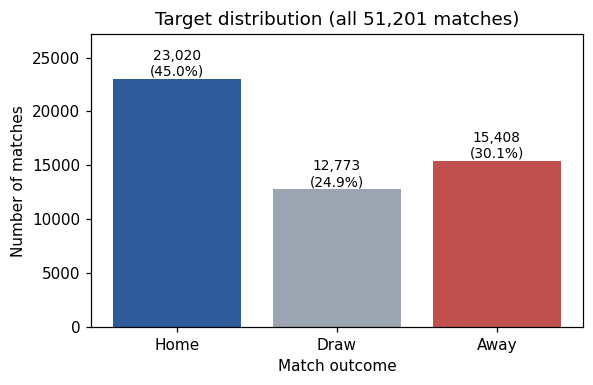

In [6]:
# ---- Class balance and the trivial benchmarks it implies ----------------------------------
shares = df_raw["target_result"].value_counts(normalize=True).reindex(CLASSES)
print("Share of each class:\n", (shares * 100).round(2).to_string())
print(f"\nAlways predicting 'H' would reach accuracy = {shares['H']:.3f} but Macro-F1 of only about "
      f"{f1_score(df_raw['target_result'], ['H'] * len(df_raw), average='macro', labels=CLASSES, zero_division=0):.3f}.")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
bars = ax.bar([CLASS_NAMES[c] for c in CLASSES], target_counts.values, color=["#2E5C9A", "#9AA5B1", "#C0504D"])
for b, v in zip(bars, target_counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(df_raw):.1%})", ha="center", va="bottom", fontsize=9)
ax.set_title("Target distribution (all 51,201 matches)"); ax.set_xlabel("Match outcome"); ax.set_ylabel("Number of matches")
ax.set_ylim(0, target_counts.max() * 1.18)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "01_target_distribution.png")); plt.show()

## 7. Chronological Train / Validation / Test Split

Football forecasting is a **time-ordered** problem. A random split would place matches from 2024 in the training set and ask the model to "predict" matches from 2019, so the model would learn from the future. It would also put the two teams' consecutive matches in different folds, inflating the apparent accuracy. A chronological split reproduces the real use case: train on the past, validate on the next season, and keep the most recent seasons untouched for the final test.

| Set | Rule |
|---|---|
| Train | `season_start <= 2022` |
| Validation | `season_start == 2023` |
| Test | `season_start >= 2024` (**untouched until Section 17**) |

In [7]:
# ---- Sort chronologically (date, then match_uid for a deterministic order) ----------------
df = df_raw.sort_values(["date", "match_uid"]).reset_index(drop=True)

train_df = df[df["season_start"] <= 2022].copy()
valid_df = df[df["season_start"] == 2023].copy()
test_df  = df[df["season_start"] >= 2024].copy()     # NOT used until the single final evaluation

split_table = pd.DataFrame({
    "matches": [len(train_df), len(valid_df), len(test_df)],
    "first_date": [d["date"].min().date() for d in (train_df, valid_df, test_df)],
    "last_date":  [d["date"].max().date() for d in (train_df, valid_df, test_df)],
    "H_%": [(d["target_result"] == "H").mean() * 100 for d in (train_df, valid_df, test_df)],
    "D_%": [(d["target_result"] == "D").mean() * 100 for d in (train_df, valid_df, test_df)],
    "A_%": [(d["target_result"] == "A").mean() * 100 for d in (train_df, valid_df, test_df)],
}, index=["Train (<= 2022)", "Validation (2023)", "Test (>= 2024)"]).round(2)
display(split_table)

# Temporal integrity checks
assert len(train_df) + len(valid_df) + len(test_df) == len(df), "Some rows fall in no split"
assert train_df["date"].max() < valid_df["date"].min() < valid_df["date"].max() < test_df["date"].min(), "Splits overlap in time"
assert set(train_df["match_uid"]).isdisjoint(valid_df["match_uid"]) and set(valid_df["match_uid"]).isdisjoint(test_df["match_uid"])
print("Temporal integrity checks passed: train < validation < test, no shared matches.")

y_train = train_df["target_result"].to_numpy(dtype=object)
y_valid = valid_df["target_result"].to_numpy(dtype=object)
y_test  = test_df["target_result"].to_numpy(dtype=object)

,matches,first_date,last_date,H_%,D_%,A_%
Train (<= 2022),42795,2008-08-09,2023-06-04,45.28,24.79,29.93
Validation (2023),2802,2023-07-28,2024-06-02,43.25,26.16,30.59
Test (>= 2024),5604,2024-07-26,2026-05-24,43.36,25.55,31.08


Temporal integrity checks passed: train < validation < test, no shared matches.


## 8. Feature Set Definition

Four **cumulative** feature sets test RQ2: does player-aware and positional information improve prediction over team form and league context alone? FS4 is not assumed to be better; it is measured.

### FS1: team form + match context
Five-match rolling form for both teams (matches played in the window, points per game, win rate, goals for / against / difference) and `league_code`.

### FS2: FS1 + starting-XI quality
Starter counts, strength evidence counts and coverage, XI strength, top-3 strength, top-3 gap, and the XI strength difference.

### FS3: FS2 + positional / matchup features
Attack, midfield, defence and goalkeeper strengths for both teams, plus the opponent-relative matchup features.

### FS4: FS3 + tactical features
Home and away formation (categorical) and lineup continuity.

In [8]:
# ---- Summarise the four cumulative feature sets -------------------------------------------
fs_table = pd.DataFrame([{"feature_set": fs, "n_columns": len(cols),
                          "n_categorical": sum(c in CATEGORICAL for c in cols),
                          "n_numeric": sum(c not in CATEGORICAL for c in cols),
                          "adds": {"FS1": "form + league", "FS2": "XI quality", "FS3": "positional + matchup", "FS4": "formation + continuity"}[fs]}
                         for fs, cols in FEATURE_SETS.items()]).set_index("feature_set")
display(fs_table)
for fs in FS_ORDER[1:]:
    prev = FS_ORDER[FS_ORDER.index(fs) - 1]
    assert set(FEATURE_SETS[prev]) < set(FEATURE_SETS[fs]), f"{fs} must strictly contain {prev}"
print("Cumulative structure verified: FS1 < FS2 < FS3 < FS4.")

# Missingness of every predictor inside the TRAIN period (reported, not filled here)
miss = (train_df[FEATURE_SETS["FS4"]].isna().mean() * 100).round(2).rename("train_missing_%").to_frame()
miss["introduced_in"] = [INTRODUCED_IN[c] for c in miss.index]
display(miss.sort_values("train_missing_%", ascending=False).head(15))

,n_columns,n_categorical,n_numeric,adds
feature_set,,,,
FS1,13,1,12,form + league
FS2,26,1,25,XI quality
FS3,38,1,37,positional + matchup
FS4,42,3,39,formation + continuity


Cumulative structure verified: FS1 < FS2 < FS3 < FS4.


,train_missing_%,introduced_in
home_lineup_continuity,8.34,FS4
away_lineup_continuity,8.33,FS4
gk_strength_diff,3.13,FS3
home_goals_for_avg_L5,2.82,FS1
home_win_rate_L5,2.82,FS1
away_win_rate_L5,2.82,FS1
home_goals_against_avg_L5,2.82,FS1
away_goals_for_avg_L5,2.82,FS1
away_points_per_game_L5,2.82,FS1
home_points_per_game_L5,2.82,FS1


## 9. Preprocessing Pipeline

Every model is a scikit-learn `Pipeline`:

`raw feature DataFrame -> ColumnTransformer -> imputation -> scaling / encoding -> classifier`

Because imputers, scalers and encoders are **steps inside the pipeline**, they are fitted only on the data passed to `.fit()` (training data, and only the training part of each fold during cross-validation). Validation and test data are only transformed, never fitted on.

* Numeric: median imputation, then `StandardScaler` for models that are scale-sensitive (Logistic Regression, Gaussian NB, kNN, baseline). Tree ensembles receive unscaled values because scaling does not change their splits.
* Categorical (`league_code`, `home_formation`, `away_formation`): most-frequent imputation, then `OneHotEncoder(handle_unknown="ignore")`, which silently ignores formation labels that were never seen in training.

In [9]:
# ---- Helpers: select X, preprocessing factory, model factory --------------------------------
def get_X(frame, features):
    # Returns a copy containing ONLY the requested columns. Categorical columns are cast to
    # plain object dtype with np.nan for missing values so scikit-learn imputers behave the same
    # under every pandas version.
    X = frame[features].copy()
    for c in features:
        if c in CATEGORICAL:
            X[c] = X[c].astype(object).where(X[c].notna(), np.nan)
    return X

def make_preprocessor(features, scale):
    num_cols = [c for c in features if c not in CATEGORICAL]
    cat_cols = [c for c in features if c in CATEGORICAL]
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    parts = [("num", Pipeline(num_steps), num_cols)]
    if cat_cols:
        parts.append(("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                       ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols))
    return ColumnTransformer(parts, remainder="drop", verbose_feature_names_out=False)

MODEL_NAMES = ["Dummy", "LogisticRegression", "GaussianNB", "kNN", "DecisionTree", "RandomForest", "GradientBoosting"]
SCALED = {"Dummy": True, "LogisticRegression": True, "GaussianNB": True, "kNN": True,
          "DecisionTree": False, "RandomForest": False, "GradientBoosting": False}

def make_classifier(name, **params):
    if name == "Dummy":
        return DummyClassifier(strategy="prior")
    if name == "LogisticRegression":
        p = dict(C=1.0, max_iter=2000, random_state=RANDOM_STATE); p.update(params)
        return LogisticRegression(**p)
    if name == "GaussianNB":
        return GaussianNB(**params)
    if name == "kNN":
        p = dict(n_neighbors=50); p.update(params)
        return KNeighborsClassifier(**p)
    if name == "DecisionTree":
        p = dict(max_depth=6, min_samples_leaf=50, random_state=RANDOM_STATE); p.update(params)
        return DecisionTreeClassifier(**p)
    if name == "RandomForest":
        p = dict(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE); p.update(params)
        return RandomForestClassifier(**p)
    if name == "GradientBoosting":
        p = dict(n_estimators=100, learning_rate=0.1, max_depth=3, subsample=0.8, random_state=RANDOM_STATE); p.update(params)
        return GradientBoostingClassifier(**p)
    raise ValueError(name)

def build_pipeline(name, features, **params):
    return Pipeline([("prep", make_preprocessor(features, SCALED[name])),
                     ("clf", make_classifier(name, **params))])

# ---- Metric helpers ------------------------------------------------------------------------
def multiclass_brier(y_true, proba):
    # Mean over matches of sum_k (p_k - 1[y = k])^2. Lower is better; columns follow CLASSES.
    onehot = np.column_stack([(y_true == c).astype(float) for c in CLASSES])
    return float(np.mean(np.sum((proba - onehot) ** 2, axis=1)))

SORTED_LABELS = sorted(CLASSES)          # ['A', 'D', 'H']: the order scikit-learn's log_loss assumes for probability columns

def safe_log_loss(y_true, proba):
    # proba columns follow CLASSES = [H, D, A]. sklearn's log_loss interprets columns in SORTED label
    # order, so the columns are re-ordered first; otherwise Home and Away probabilities would be swapped.
    idx = [CLASSES.index(c) for c in SORTED_LABELS]
    return log_loss(y_true, proba[:, idx], labels=SORTED_LABELS)

# Unit test of the helper against a manual calculation: -mean(log(probability assigned to the true class))
_p = np.array([[0.7, 0.2, 0.1], [0.1, 0.3, 0.6]])            # columns: H, D, A
_y = np.array(["H", "A"], dtype=object)
assert abs(safe_log_loss(_y, _p) - (-np.mean(np.log([0.7, 0.6])))) < 1e-9, "log-loss column order is wrong"

def evaluate(pipe, X, y):
    # Returns metrics + predictions. Probabilities are re-ordered to CLASSES = [H, D, A].
    raw = pipe.predict_proba(X)
    order = [list(pipe.classes_).index(c) for c in CLASSES]
    proba = raw[:, order]
    pred = pipe.predict(X)
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=CLASSES, zero_division=0)
    out = {"Accuracy": accuracy_score(y, pred),
           "Balanced Accuracy": balanced_accuracy_score(y, pred),
           "Macro-F1": f1_score(y, pred, average="macro", labels=CLASSES, zero_division=0),
           "Weighted-F1": f1_score(y, pred, average="weighted", labels=CLASSES, zero_division=0),
           "Log Loss": safe_log_loss(y, proba),
           "Brier Score": multiclass_brier(y, proba)}
    for i, c in enumerate(CLASSES):
        out[f"{CLASS_NAMES[c]} Precision"], out[f"{CLASS_NAMES[c]} Recall"], out[f"{CLASS_NAMES[c]} F1"] = p[i], r[i], f[i]
    return out, pred, proba

print("Helpers defined. Models:", MODEL_NAMES)

Helpers defined. Models: ['Dummy', 'LogisticRegression', 'GaussianNB', 'kNN', 'DecisionTree', 'RandomForest', 'GradientBoosting']


## 10. Baseline Model

`DummyClassifier(strategy="prior")` ignores every feature and outputs the **training class proportions** as its probabilities. It is the reference every real model must beat: a model that cannot outperform it has learned nothing beyond the class balance. The baseline matters especially here because "always predict Home" already gives a respectable accuracy while having a very low Macro-F1.

In [10]:
# ---- Dummy baseline (prior strategy), evaluated on VALIDATION only --------------------------
feats_fs1 = FEATURE_SETS["FS1"]
dummy_pipe = build_pipeline("Dummy", feats_fs1).fit(get_X(train_df, feats_fs1), y_train)
dummy_val, dummy_val_pred, dummy_val_proba = evaluate(dummy_pipe, get_X(valid_df, feats_fs1), y_valid)

print("Training class priors used as probabilities:",
      dict(zip(dummy_pipe.classes_, dummy_pipe.named_steps["clf"].class_prior_.round(4))))
print("Dummy predicts only:", np.unique(dummy_val_pred))
display(pd.Series({k: dummy_val[k] for k in ["Accuracy", "Balanced Accuracy", "Macro-F1", "Weighted-F1", "Log Loss", "Brier Score"]},
                  name="Dummy (prior), validation").round(4).to_frame())

Training class priors used as probabilities: {'A': np.float64(0.2993), 'D': np.float64(0.2479), 'H': np.float64(0.4528)}
Dummy predicts only: ['H']


,"Dummy (prior), validation"
Accuracy,0.4325
Balanced Accuracy,0.3333
Macro-F1,0.2013
Weighted-F1,0.2612
Log Loss,1.0765
Brier Score,0.6516


## 11. Candidate Models

The models differ in their **modelling assumptions**, which is the purpose of the comparison.

| Model | Assumption it represents |
|---|---|
| Dummy (prior) | No information in the features; class frequencies only |
| Multinomial Logistic Regression | Linear log-odds in the (scaled) features; interpretable coefficients |
| Gaussian Naive Bayes | Conditionally independent, Gaussian-distributed features per class |
| k-Nearest Neighbours | Similar historical matches have similar outcomes; local, non-parametric |
| Decision Tree | A single interpretable set of axis-aligned splits |
| Random Forest | Bagged trees; non-linear interactions with variance reduction |
| Gradient Boosting | Sequentially fitted shallow trees; non-linear, bias reduction |

An MLP is optional in the brief and is not added, to keep the comparison focused. Default hyperparameters are set once for the ablation (Section 12) and tuned later (Section 14) only for the strongest candidates. No SMOTE or other resampling is used; class imbalance is handled with class weights (Section 15), which keeps the training data untouched.

## 12. FS1 to FS4 Ablation Study

Every model is trained on the **same training period**, scored on the **same validation period** with the **same preprocessing** and the **same metrics**, for each of the four feature sets. No test data is used.

In [11]:
# ---- Ablation: every feature set x every model, fitted on TRAIN, scored on VALIDATION -------
val_rows, VAL_PRED = [], {}
for fs in FS_ORDER:
    feats = FEATURE_SETS[fs]
    X_tr, X_va = get_X(train_df, feats), get_X(valid_df, feats)
    for name in MODEL_NAMES:
        t0 = time.time()
        pipe = build_pipeline(name, feats).fit(X_tr, y_train)
        m, pred, proba = evaluate(pipe, X_va, y_valid)
        val_rows.append({"Feature Set": fs, "Model": name, **m, "Seconds": round(time.time() - t0, 1)})
        VAL_PRED[(fs, name)] = (pred, proba)
        print(f"{fs} | {name:<18} Macro-F1 = {m['Macro-F1']:.4f}  Acc = {m['Accuracy']:.4f}  LogLoss = {m['Log Loss']:.4f}  ({time.time() - t0:.0f}s)")

ablation = pd.DataFrame(val_rows)
main_cols = ["Feature Set", "Model", "Accuracy", "Balanced Accuracy", "Macro-F1", "Weighted-F1", "Log Loss", "Brier Score"]
os.makedirs(OUT_DIR, exist_ok=True)
ablation.to_csv(os.path.join(OUT_DIR, "ablation_validation_results.csv"), index=False)
display(ablation[main_cols].round(4))

FS1 | Dummy              Macro-F1 = 0.2013  Acc = 0.4325  LogLoss = 1.0765  (0s)


FS1 | LogisticRegression Macro-F1 = 0.3523  Acc = 0.4911  LogLoss = 1.0193  (1s)
FS1 | GaussianNB         Macro-F1 = 0.3918  Acc = 0.4793  LogLoss = 1.2496  (0s)


FS1 | kNN                Macro-F1 = 0.3717  Acc = 0.4825  LogLoss = 1.0366  (1s)
FS1 | DecisionTree       Macro-F1 = 0.3471  Acc = 0.4879  LogLoss = 1.0179  (0s)


FS1 | RandomForest       Macro-F1 = 0.3623  Acc = 0.4807  LogLoss = 1.0270  (8s)


FS1 | GradientBoosting   Macro-F1 = 0.3518  Acc = 0.4911  LogLoss = 1.0160  (12s)
FS2 | Dummy              Macro-F1 = 0.2013  Acc = 0.4325  LogLoss = 1.0765  (0s)


...

FS4 | kNN                Macro-F1 = 0.4163  Acc = 0.5261  LogLoss = 0.9843  (2s)


FS4 | DecisionTree       Macro-F1 = 0.3986  Acc = 0.5325  LogLoss = 0.9719  (1s)


FS4 | RandomForest       Macro-F1 = 0.4088  Acc = 0.5403  LogLoss = 0.9689  (25s)


FS4 | GradientBoosting   Macro-F1 = 0.4093  Acc = 0.5410  LogLoss = 0.9625  (98s)


,Feature Set,Model,Accuracy,Balanced Accuracy,Macro-F1,Weighted-F1,Log Loss,Brier Score
0,FS1,Dummy,0.4325,0.3333,0.2013,0.2612,1.0765,0.6516
1,FS1,LogisticRegression,0.4911,0.4163,0.3523,0.4030,1.0193,0.6105
2,FS1,GaussianNB,0.4793,0.4285,0.3918,0.4324,1.2496,0.6795
3,FS1,kNN,0.4825,0.4160,0.3717,0.4162,1.0366,0.6201
4,FS1,DecisionTree,0.4879,0.4084,0.3471,0.3972,1.0179,0.6099
5,FS1,RandomForest,0.4807,0.4113,0.3623,0.4082,1.0270,0.6154
6,FS1,GradientBoosting,0.4911,0.4153,0.3518,0.4025,1.0160,0.6085
7,FS2,Dummy,0.4325,0.3333,0.2013,0.2612,1.0765,0.6516
8,FS2,LogisticRegression,0.5389,0.4703,0.4027,0.4535,0.9660,0.5749
9,FS2,GaussianNB,0.5236,0.4841,0.4636,0.4972,1.4674,0.6850


Validation Macro-F1 by model and feature set:


Feature Set,FS1,FS2,FS3,FS4
Model,,,,
Dummy,0.2013,0.2013,0.2013,0.2013
LogisticRegression,0.3523,0.4027,0.4025,0.4057
GaussianNB,0.3918,0.4636,0.4727,0.3732
kNN,0.3717,0.4290,0.4141,0.4163
DecisionTree,0.3471,0.4057,0.4003,0.3986
RandomForest,0.3623,0.4152,0.4102,0.4088
GradientBoosting,0.3518,0.4060,0.4072,0.4093


Change vs FS1 (same model), in Macro-F1 points:


Feature Set,FS1,FS2,FS3,FS4
Model,,,,
Dummy,0.0,0.0000,0.0000,0.0000
LogisticRegression,0.0,0.0505,0.0503,0.0535
GaussianNB,0.0,0.0718,0.0809,-0.0186
kNN,0.0,0.0574,0.0424,0.0446
DecisionTree,0.0,0.0585,0.0532,0.0515
RandomForest,0.0,0.0529,0.0479,0.0465
GradientBoosting,0.0,0.0542,0.0554,0.0575


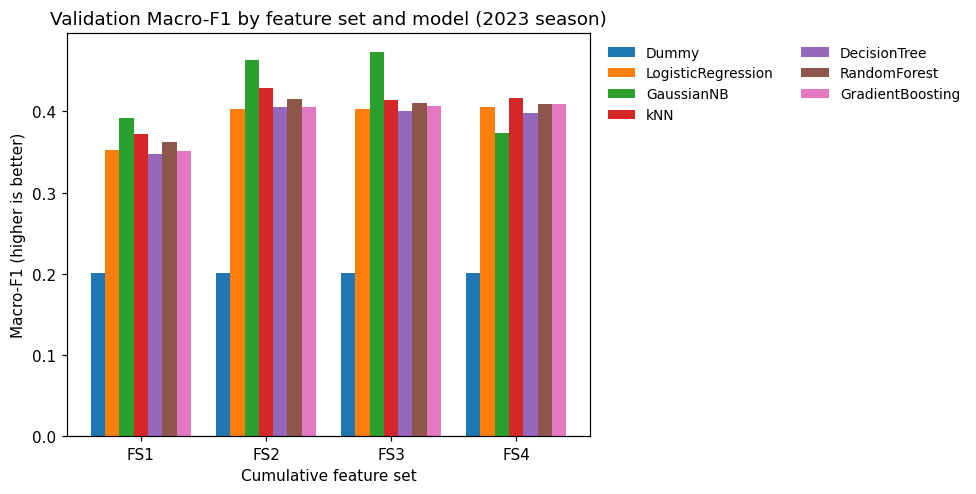

In [12]:
# ---- Macro-F1 pivot and change relative to FS1 (same model) -------------------------------
pivot = ablation.pivot(index="Model", columns="Feature Set", values="Macro-F1").loc[MODEL_NAMES, FS_ORDER]
print("Validation Macro-F1 by model and feature set:")
display(pivot.round(4))
print("Change vs FS1 (same model), in Macro-F1 points:")
display(pivot.sub(pivot["FS1"], axis=0).round(4))

# ---- Figure: FS1-FS4 Macro-F1 comparison ---------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.6))
width = 0.8 / len(MODEL_NAMES)
for i, name in enumerate(MODEL_NAMES):
    ax.bar(np.arange(4) + i * width, pivot.loc[name].values, width, label=name)
ax.set_xticks(np.arange(4) + 0.4 - width / 2); ax.set_xticklabels(FS_ORDER)
ax.set_title("Validation Macro-F1 by feature set and model (2023 season)")
ax.set_xlabel("Cumulative feature set"); ax.set_ylabel("Macro-F1 (higher is better)")
ax.legend(ncol=2, loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "02_fs_ablation_macro_f1.png"), bbox_inches="tight"); plt.show()

### 12.1 Is the FS1 to FS4 difference larger than noise?
The validation season contains only a few thousand matches, so a difference of a few thousandths in Macro-F1 may be noise. A **paired bootstrap** (the same resampled matches for both feature sets) gives an interval for the difference. For each feature set the best non-baseline model is used; note that taking the best of several models favours each set slightly (winner's-curse), so read the intervals as indicative, not as formal tests.

In [13]:
# ---- Fast Macro-F1 for bootstrapping (verified against scikit-learn below) -----------------
L2I = {c: i for i, c in enumerate(CLASSES)}
def to_int(a): return np.array([L2I[x] for x in a])

def fast_macro_f1(yi, pi):
    cm = np.bincount(yi * 3 + pi, minlength=9).reshape(3, 3)
    tp = np.diag(cm).astype(float); denom = cm.sum(0) + cm.sum(1)
    f1 = np.divide(2 * tp, denom, out=np.zeros(3), where=denom > 0)
    return f1.mean()

_chk_p = to_int(VAL_PRED[("FS1", "RandomForest")][0]); _chk_y = to_int(y_valid)
assert abs(fast_macro_f1(_chk_y, _chk_p) - f1_score(y_valid, VAL_PRED[("FS1", "RandomForest")][0], average="macro", labels=CLASSES)) < 1e-9

def bootstrap_ci(yi, pi, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed); n = len(yi)
    vals = np.array([fast_macro_f1(yi[idx], pi[idx]) for idx in (rng.integers(0, n, n) for _ in range(n_boot))])
    return np.percentile(vals, [2.5, 97.5])

def paired_bootstrap_delta(yi, p_new, p_base, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed); n = len(yi); d = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        d.append(fast_macro_f1(yi[idx], p_new[idx]) - fast_macro_f1(yi[idx], p_base[idx]))
    return np.percentile(d, [2.5, 97.5])

cand = ablation[ablation["Model"] != "Dummy"]
best_per_fs = cand.loc[cand.groupby("Feature Set")["Macro-F1"].idxmax()].set_index("Feature Set").loc[FS_ORDER]
yv_i = to_int(y_valid)
base_pred = to_int(VAL_PRED[("FS1", best_per_fs.loc["FS1", "Model"])][0])
rq2_rows = []
for fs in FS_ORDER:
    mdl = best_per_fs.loc[fs, "Model"]
    pred_i = to_int(VAL_PRED[(fs, mdl)][0])
    delta = best_per_fs.loc[fs, "Macro-F1"] - best_per_fs.loc["FS1", "Macro-F1"]
    lo, hi = (np.nan, np.nan) if fs == "FS1" else paired_bootstrap_delta(yv_i, pred_i, base_pred)
    rq2_rows.append({"Feature Set": fs, "Best model": mdl, "Macro-F1": best_per_fs.loc[fs, "Macro-F1"],
                     "Delta vs FS1 best": delta, "95% CI low": lo, "95% CI high": hi,
                     "CI excludes 0": (None if fs == "FS1" else bool(lo > 0 or hi < 0))})
rq2_table = pd.DataFrame(rq2_rows)
display(rq2_table.round(4))

,Feature Set,Best model,Macro-F1,Delta vs FS1 best,95% CI low,95% CI high,CI excludes 0
0,FS1,GaussianNB,0.3918,0.0000,NaN,NaN,None
1,FS2,GaussianNB,0.4636,0.0718,0.0545,0.0891,True
2,FS3,GaussianNB,0.4727,0.0809,0.0632,0.1009,True
3,FS4,kNN,0.4163,0.0245,0.0071,0.0427,True


## 13. Class-wise Evaluation

Overall accuracy can hide a model that never predicts the Draw class. The table below gives precision, recall and F1 for **Home**, **Draw** and **Away** for the strongest candidates and the baseline, followed by confusion matrices. All numbers are validation results.

Macro-F1  Accuracy  Home Precision  Home Recall  \
Feature Set Model                                                           
FS1         Dummy           0.2013    0.4325          0.4325       1.0000   
FS3         GaussianNB      0.4727    0.5200          0.6110       0.6427   
FS2         GaussianNB      0.4636    0.5236          0.6020       0.6790   
            kNN             0.4290    0.5339          0.5467       0.8160   
FS4         kNN             0.4163    0.5261          0.5416       0.8160   
FS2         RandomForest    0.4152    0.5382          0.5366       0.8465   

                          Home F1  Draw Precision  Draw Recall  Draw F1  \
Feature Set Model                                                         
FS1         Dummy          0.6039          0.0000       0.0000   0.0000   
FS3         GaussianNB     0.6265          0.3138       0.1896   0.2364   
FS2         GaussianNB     0.6382          0.3188       0.1501   0.2041   
            kNN            0.6548          0.3040       0.0518   0.0886   
FS4         kNN            0.6511          0.2456       0.0382   0.0661   
FS2         RandomForest   0.6569          0.3556       0.0218   0.0411   

                          Away Precision  Away Recall  Away F1  
Feature Set Model                                               
FS1         Dummy                 0.0000       0.0000   0.0000  
FS3         GaussianNB            0.4972       0.6289   0.5554  
FS2         GaussianNB            0.4899       0.6231   0.5485  
            kNN                   0.5403       0.5473   0.5438  
FS4         kNN                   0.5302       0.5333   0.5317  
FS2         RandomForest          0.5515       0.5438   0.5476

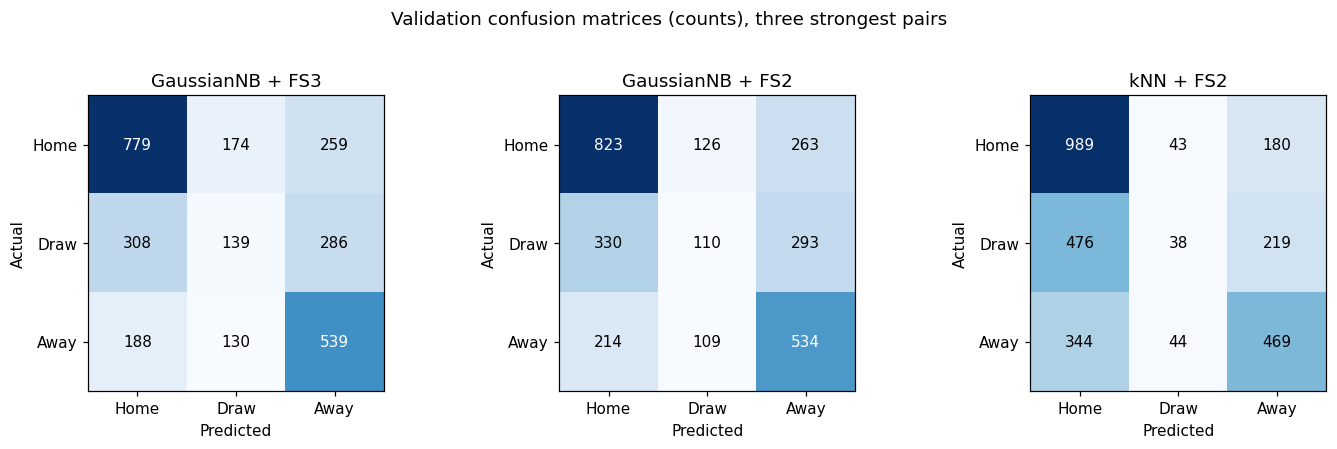

Draw recall / F1 across the listed pairs (Draw is the hardest class):


Draw Precision  Draw Recall  Draw F1
Feature Set Model                                             
FS1         Dummy                 0.0000       0.0000   0.0000
FS3         GaussianNB            0.3138       0.1896   0.2364
FS2         GaussianNB            0.3188       0.1501   0.2041
            kNN                   0.3040       0.0518   0.0886
FS4         kNN                   0.2456       0.0382   0.0661
FS2         RandomForest          0.3556       0.0218   0.0411

In [14]:
# ---- Class-wise metrics for the baseline and the five strongest (feature set, model) pairs --
top5 = cand.sort_values("Macro-F1", ascending=False).head(5)[["Feature Set", "Model"]].values.tolist()
show = [("FS1", "Dummy")] + [tuple(x) for x in top5]
class_cols = [f"{CLASS_NAMES[c]} {m}" for c in CLASSES for m in ("Precision", "Recall", "F1")]
cw_table = ablation.set_index(["Feature Set", "Model"]).loc[show, ["Macro-F1", "Accuracy"] + class_cols]
display(cw_table.round(4))

# ---- Confusion matrices for the best three pairs on validation ---------------------------
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (fs, mdl) in zip(axes, [tuple(x) for x in top5[:3]]):
    pred = VAL_PRED[(fs, mdl)][0]
    cm = confusion_matrix(y_valid, pred, labels=CLASSES)
    im = ax.imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels([CLASS_NAMES[c] for c in CLASSES]); ax.set_yticklabels([CLASS_NAMES[c] for c in CLASSES])
    ax.set_title(f"{mdl} + {fs}"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.suptitle("Validation confusion matrices (counts), three strongest pairs", y=1.03)
plt.tight_layout(); plt.show()

print("Draw recall / F1 across the listed pairs (Draw is the hardest class):")
display(cw_table[["Draw Precision", "Draw Recall", "Draw F1"]].round(4))

## 14. Hyperparameter Tuning (temporal, training period only)

**Selection of what to tune.** The feature set is taken from the ablation: the set whose best model has the highest validation Macro-F1 (`PARSIMONY_TOL = 0` means a strict maximum, so nothing is assumed in favour of larger sets; raise it to prefer the simplest set within a tolerance). Only the **three strongest model families** at that feature set are tuned.

**How it is tuned.** `GridSearchCV` with `TimeSeriesSplit(n_splits=3)` **inside the training period**: each fold trains on earlier matches and scores on the next block, with `scoring="f1_macro"`. The 2023 validation season and the 2024+ test set play no role in the search. In scikit-learn's `LogisticRegression`, `C` is the **inverse** of the regularisation strength: a smaller `C` means stronger regularisation.

In [15]:
# ---- Choose the feature set from the ablation (validation Macro-F1) ------------------------
PARSIMONY_TOL = 0.0          # 0.0 = strict maximum; e.g. 0.005 would prefer the smallest set within 0.005 of the best
best_fs_scores = best_per_fs["Macro-F1"]
eligible = best_fs_scores[best_fs_scores >= best_fs_scores.max() - PARSIMONY_TOL].index.tolist()
SELECTED_FS = [fs for fs in FS_ORDER if fs in eligible][0]
SEL_FEATS = FEATURE_SETS[SELECTED_FS]
print("Best validation Macro-F1 per feature set:\n", best_fs_scores.round(4).to_string())
print(f"\nSelected feature set: {SELECTED_FS} ({len(SEL_FEATS)} columns)")

at_fs = cand[cand["Feature Set"] == SELECTED_FS].sort_values("Macro-F1", ascending=False)
TUNE_MODELS = at_fs["Model"].head(3).tolist()
print("Models to tune (top 3 at this feature set):", TUNE_MODELS)
display(at_fs[main_cols].round(4))

Best validation Macro-F1 per feature set:
 Feature Set
FS1    0.3918
FS2    0.4636
FS3    0.4727
FS4    0.4163

Selected feature set: FS3 (38 columns)
Models to tune (top 3 at this feature set): ['GaussianNB', 'kNN', 'RandomForest']


,Feature Set,Model,Accuracy,Balanced Accuracy,Macro-F1,Weighted-F1,Log Loss,Brier Score
16,FS3,GaussianNB,0.5200,0.4871,0.4727,0.5027,2.3555,0.7634
17,FS3,kNN,0.5218,0.4588,0.4141,0.4590,0.9939,0.5842
19,FS3,RandomForest,0.5350,0.4674,0.4102,0.4578,0.9701,0.5765
20,FS3,GradientBoosting,0.5400,0.4705,0.4072,0.4567,0.9640,0.5728
15,FS3,LogisticRegression,0.5382,0.4700,0.4025,0.4532,0.9661,0.5750
18,FS3,DecisionTree,0.5325,0.4622,0.4003,0.4498,0.9712,0.5782


In [16]:
# ---- Hyperparameter grids (kept small and explicit) ----------------------------------------
GRIDS = {
    "LogisticRegression": {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]},
    "GaussianNB":         {"clf__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-1]},
    "kNN":                {"clf__n_neighbors": [25, 50, 100, 200], "clf__weights": ["uniform", "distance"]},
    "DecisionTree":       {"clf__max_depth": [3, 5, 8], "clf__min_samples_leaf": [20, 50, 100], "clf__class_weight": [None, "balanced"]},
    "RandomForest":       {"clf__max_depth": [6, 12], "clf__min_samples_leaf": [5, 20], "clf__class_weight": [None, "balanced"]},
    "GradientBoosting":   [{"clf__n_estimators": [100], "clf__learning_rate": [0.1],  "clf__max_depth": [2]},
                           {"clf__n_estimators": [100], "clf__learning_rate": [0.1],  "clf__max_depth": [3]},
                           {"clf__n_estimators": [150], "clf__learning_rate": [0.05], "clf__max_depth": [3]},
                           {"clf__n_estimators": [100], "clf__learning_rate": [0.05], "clf__max_depth": [4]}],
}
tscv = TimeSeriesSplit(n_splits=3)            # expanding-window temporal folds; train is already date-sorted
X_tr_sel, X_va_sel = get_X(train_df, SEL_FEATS), get_X(valid_df, SEL_FEATS)

TUNED, tuned_rows, TUNED_VAL_PRED = {}, [], {}
for name in TUNE_MODELS:
    t0 = time.time()
    gs = GridSearchCV(build_pipeline(name, SEL_FEATS), GRIDS[name], scoring="f1_macro", cv=tscv, n_jobs=1, refit=True)
    gs.fit(X_tr_sel, y_train)
    params = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
    m, pred, proba = evaluate(gs.best_estimator_, X_va_sel, y_valid)
    weight = params.pop("class_weight", None)
    TUNED[name] = {"params": params, "weight": weight, "cv_macro_f1": gs.best_score_}
    TUNED_VAL_PRED[name] = (pred, proba)
    tuned_rows.append({"Feature Set": SELECTED_FS, "Model": name, "Best params": str({**params, "class_weight": weight}),
                       "Temporal CV Macro-F1": gs.best_score_, **{k: m[k] for k in main_cols[2:]}})
    print(f"{name:<18} CV Macro-F1 = {gs.best_score_:.4f} | validation Macro-F1 = {m['Macro-F1']:.4f} | best = {gs.best_params_} ({time.time() - t0:.0f}s)")

tuned_table = pd.DataFrame(tuned_rows)
tuned_table.to_csv(os.path.join(OUT_DIR, "tuned_validation_results.csv"), index=False)
display(tuned_table.round(4))

GaussianNB         CV Macro-F1 = 0.4586 | validation Macro-F1 = 0.4727 | best = {'clf__var_smoothing': 0.001} (2s)


kNN                CV Macro-F1 = 0.4243 | validation Macro-F1 = 0.4369 | best = {'clf__n_neighbors': 25, 'clf__weights': 'uniform'} (39s)


RandomForest       CV Macro-F1 = 0.4696 | validation Macro-F1 = 0.4916 | best = {'clf__class_weight': 'balanced', 'clf__max_depth': 6, 'clf__min_samples_leaf': 5} (199s)


,Feature Set,Model,Best params,Temporal CV Macro-F1,Accuracy,Balanced Accuracy,Macro-F1,Weighted-F1,Log Loss,Brier Score
0,FS3,GaussianNB,"{'var_smoothing': 0.001, 'class_weight': None}",0.4586,0.5200,0.4871,0.4727,0.5027,2.3530,0.7632
1,FS3,kNN,"{'n_neighbors': 25, 'weights': 'uniform', 'cla...",0.4243,0.5178,0.4641,0.4369,0.4747,1.0961,0.5960
2,FS3,RandomForest,"{'max_depth': 6, 'min_samples_leaf': 5, 'class...",0.4696,0.5061,0.4929,0.4916,0.5113,0.9835,0.5874


## 15. Draw-Class Experiment

Draw is the minority class and, in football, the hardest to call. `class_weight="balanced"` re-weights errors so that Draw mistakes count more. It is **not** assumed to be better: it typically raises Draw recall while costing precision and overall accuracy, and it can distort probabilities. Both settings are compared on validation using the tuned hyperparameters (Gradient Boosting has no `class_weight` option, so balanced `sample_weight` is passed to `fit` instead).

LogisticRegression class_weight=None      Macro-F1=0.4025  Draw P/R/F1 = 0.000/0.000/0.000  LogLoss=0.9661


LogisticRegression class_weight=balanced  Macro-F1=0.4846  Draw P/R/F1 = 0.321/0.229/0.267  LogLoss=0.9836


DecisionTree       class_weight=None      Macro-F1=0.4003  Draw P/R/F1 = 0.190/0.005/0.011  LogLoss=0.9712


DecisionTree       class_weight=balanced  Macro-F1=0.4779  Draw P/R/F1 = 0.294/0.393/0.337  LogLoss=0.9934


RandomForest       class_weight=None      Macro-F1=0.3971  Draw P/R/F1 = 0.000/0.000/0.000  LogLoss=0.9659


RandomForest       class_weight=balanced  Macro-F1=0.4916  Draw P/R/F1 = 0.314/0.357/0.334  LogLoss=0.9835


GradientBoosting   class_weight=None      Macro-F1=0.4072  Draw P/R/F1 = 0.267/0.005/0.011  LogLoss=0.9640


GradientBoosting   class_weight=balanced  Macro-F1=0.4910  Draw P/R/F1 = 0.309/0.340/0.324  LogLoss=0.9802


,Model,class_weight,Macro-F1,Draw Precision,Draw Recall,Draw F1,Accuracy,Log Loss
0,LogisticRegression,None,0.4025,0.0000,0.0000,0.0000,0.5382,0.9661
1,LogisticRegression,balanced,0.4846,0.3206,0.2292,0.2673,0.5236,0.9836
2,DecisionTree,None,0.4003,0.1905,0.0055,0.0106,0.5325,0.9712
3,DecisionTree,balanced,0.4779,0.2945,0.3929,0.3366,0.4868,0.9934
4,RandomForest,None,0.3971,0.0000,0.0000,0.0000,0.5335,0.9659
5,RandomForest,balanced,0.4916,0.3138,0.3574,0.3342,0.5061,0.9835
6,GradientBoosting,None,0.4072,0.2667,0.0055,0.0107,0.5400,0.9640
7,GradientBoosting,balanced,0.4910,0.3089,0.3397,0.3236,0.5075,0.9802


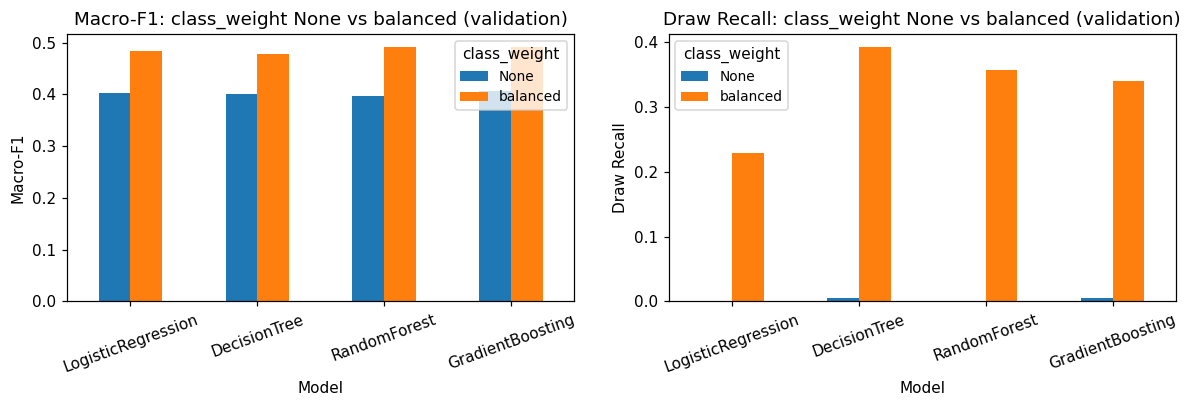

In [17]:
# ---- Fit a configuration from scratch on a training frame -----------------------------------
def fit_config(cfg, train_frame, y_tr):
    feats = FEATURE_SETS[cfg["fs"]]; name = cfg["model"]; params = dict(cfg["params"]); weight = cfg.get("weight")
    X = get_X(train_frame, feats)
    if name in ("LogisticRegression", "RandomForest", "DecisionTree"):
        params["class_weight"] = weight                       # None or "balanced"
        return build_pipeline(name, feats, **params).fit(X, y_tr)
    if name == "GradientBoosting" and weight == "balanced":
        pipe = build_pipeline(name, feats, **params)
        return pipe.fit(X, y_tr, clf__sample_weight=compute_sample_weight("balanced", y_tr))
    return build_pipeline(name, feats, **params).fit(X, y_tr)

WEIGHTABLE = ["LogisticRegression", "DecisionTree", "RandomForest", "GradientBoosting"]
draw_rows, DRAW_CFGS = [], []
for name in WEIGHTABLE:
    base = TUNED[name]["params"] if name in TUNED else {}
    for weight in (None, "balanced"):
        cfg = {"fs": SELECTED_FS, "model": name, "params": base, "weight": weight}
        pipe = fit_config(cfg, train_df, y_train)
        m, pred, proba = evaluate(pipe, X_va_sel, y_valid)
        draw_rows.append({"Model": name, "class_weight": str(weight), "Macro-F1": m["Macro-F1"], "Draw Precision": m["Draw Precision"],
                          "Draw Recall": m["Draw Recall"], "Draw F1": m["Draw F1"], "Accuracy": m["Accuracy"], "Log Loss": m["Log Loss"]})
        DRAW_CFGS.append((cfg, m))
        print(f"{name:<18} class_weight={str(weight):<9} Macro-F1={m['Macro-F1']:.4f}  Draw P/R/F1 = {m['Draw Precision']:.3f}/{m['Draw Recall']:.3f}/{m['Draw F1']:.3f}  LogLoss={m['Log Loss']:.4f}")

draw_table = pd.DataFrame(draw_rows)
display(draw_table.round(4))

# Plot: Draw recall and Macro-F1, unweighted vs balanced
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metric in zip(axes, ["Macro-F1", "Draw Recall"]):
    pv = draw_table.pivot(index="Model", columns="class_weight", values=metric).loc[WEIGHTABLE]
    pv.plot.bar(ax=ax, rot=20); ax.set_title(f"{metric}: class_weight None vs balanced (validation)")
    ax.set_xlabel("Model"); ax.set_ylabel(metric); ax.legend(title="class_weight")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "03_draw_class_weighting.png")); plt.show()

## 16. Final Model Selection (validation only)

The candidate pool is: the untuned default of each non-baseline model at the selected feature set, the tuned models, and the weighted / unweighted variants from Section 15. The final configuration is the candidate with the highest **validation Macro-F1**; Log Loss is used only to break an exact tie and is reported as a secondary diagnostic, not as a replacement criterion.

Because many candidates are compared on a single validation season, the winning score is somewhat optimistic; the test set (Section 17) is the unbiased check.

,Candidate,Model,Class Weight,Macro-F1,Accuracy,Log Loss,Draw F1
0,RandomForest (tuned),RandomForest,balanced,0.4916,0.5061,0.9835,NaN
1,"RandomForest (tuned params, class_weight=balan...",RandomForest,balanced,0.4916,0.5061,0.9835,0.3342
2,"GradientBoosting (tuned params, class_weight=b...",GradientBoosting,balanced,0.4910,0.5075,0.9802,0.3236
3,"LogisticRegression (tuned params, class_weight...",LogisticRegression,balanced,0.4846,0.5236,0.9836,0.2673
4,"DecisionTree (tuned params, class_weight=balan...",DecisionTree,balanced,0.4779,0.4868,0.9934,0.3366
5,GaussianNB (tuned),GaussianNB,None,0.4727,0.5200,2.3530,NaN
6,GaussianNB (default),GaussianNB,None,0.4727,0.5200,2.3555,0.2364
7,kNN (tuned),kNN,None,0.4369,0.5178,1.0961,NaN
8,kNN (default),kNN,None,0.4141,0.5218,0.9939,0.0675
9,RandomForest (default),RandomForest,None,0.4102,0.5350,0.9701,0.0337



Selected by validation Macro-F1: RandomForest (tuned)


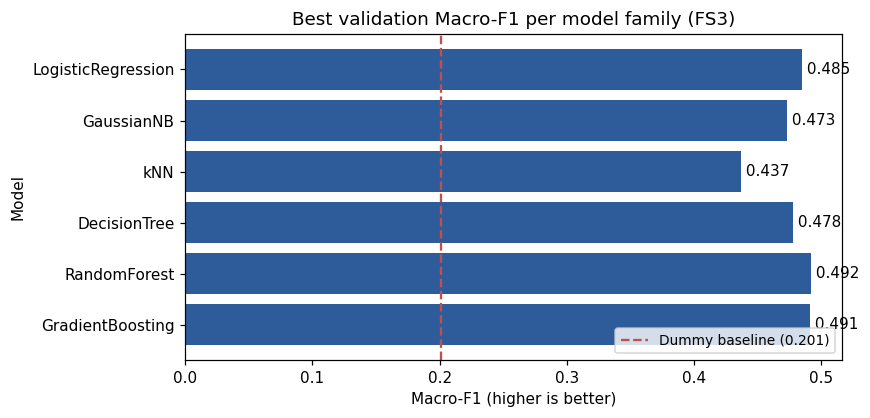

In [18]:
# ---- Build the candidate pool and rank by validation Macro-F1 ----------------------------
pool = []
for name in [m for m in MODEL_NAMES if m != "Dummy"]:
    row = ablation[(ablation["Feature Set"] == SELECTED_FS) & (ablation["Model"] == name)].iloc[0]
    pool.append({"label": f"{name} (default)", "cfg": {"fs": SELECTED_FS, "model": name, "params": {}, "weight": None}, "m": row.to_dict()})
for name, t in TUNED.items():
    row = tuned_table[tuned_table["Model"] == name].iloc[0]
    pool.append({"label": f"{name} (tuned)", "cfg": {"fs": SELECTED_FS, "model": name, "params": t["params"], "weight": t["weight"]}, "m": row.to_dict()})
for cfg, m in DRAW_CFGS:
    pool.append({"label": f"{cfg['model']} (tuned params, class_weight={cfg['weight']})", "cfg": cfg, "m": m})

rank = pd.DataFrame([{"Candidate": p["label"], "Model": p["cfg"]["model"], "Class Weight": str(p["cfg"].get("weight")),
                      "Macro-F1": p["m"]["Macro-F1"], "Accuracy": p["m"]["Accuracy"], "Log Loss": p["m"]["Log Loss"],
                      "Draw F1": p["m"].get("Draw F1", np.nan)} for p in pool])
order = rank.sort_values(["Macro-F1", "Log Loss"], ascending=[False, True]).index
rank = rank.loc[order].reset_index(drop=True)
display(rank.round(4).head(15))
rank.to_csv(os.path.join(OUT_DIR, "candidate_ranking_validation.csv"), index=False)

FINAL = pool[order[0]]
FINAL_CFG = FINAL["cfg"]
print("\nSelected by validation Macro-F1:", FINAL["label"])

# ---- Model-comparison figure at the selected feature set ---------------------------------
best_by_model = rank.groupby("Model")["Macro-F1"].max().reindex([m for m in MODEL_NAMES if m != "Dummy"])
fig, ax = plt.subplots(figsize=(8, 3.9))
ax.barh(best_by_model.index[::-1], best_by_model.values[::-1], color="#2E5C9A")
ax.axvline(dummy_val["Macro-F1"], color="#C0504D", ls="--", label=f"Dummy baseline ({dummy_val['Macro-F1']:.3f})")
for i, v in enumerate(best_by_model.values[::-1]):
    ax.text(v, i, f" {v:.3f}", va="center")
ax.set_title(f"Best validation Macro-F1 per model family ({SELECTED_FS})"); ax.set_xlabel("Macro-F1 (higher is better)"); ax.set_ylabel("Model")
ax.legend(loc="lower right"); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "04_model_comparison.png")); plt.show()

In [19]:
# ---- Freeze: refit the chosen configuration from scratch on the TRAINING data only --------
final_pipe = fit_config(FINAL_CFG, train_df, y_train)
final_val, final_val_pred, final_val_proba = evaluate(final_pipe, X_va_sel if FINAL_CFG["fs"] == SELECTED_FS else get_X(valid_df, FEATURE_SETS[FINAL_CFG["fs"]]), y_valid)
assert abs(final_val["Macro-F1"] - FINAL["m"]["Macro-F1"]) < 1e-9, "Refit does not reproduce the selected validation score"
print("Refit reproduces the validation Macro-F1:", round(final_val["Macro-F1"], 4))

FINAL_FEATS = FEATURE_SETS[FINAL_CFG["fs"]]
prep_desc = ("Numeric: median imputation" + (" + StandardScaler" if SCALED[FINAL_CFG["model"]] else "") +
             "; Categorical: most-frequent imputation + OneHotEncoder(handle_unknown='ignore'); all fitted on training data only")
final_config_table = pd.DataFrame([{
    "Final Feature Set": FINAL_CFG["fs"],
    "Final Model": FINAL_CFG["model"],
    "Hyperparameters": str(FINAL_CFG["params"]) if FINAL_CFG["params"] else "library/notebook defaults",
    "Class Weight": str(FINAL_CFG.get("weight")),
    "Preprocessing": prep_desc,
    "Calibration": "none (raw predict_proba)",
    "Training data": "season_start <= 2022 only",
    "Selection Metric": "Validation Macro-F1 (season_start == 2023)",
    "Validation Macro-F1": round(final_val["Macro-F1"], 4),
    "Random State": RANDOM_STATE}]).T.rename(columns={0: "Frozen configuration"})
final_config_table.to_csv(os.path.join(OUT_DIR, "final_model_selection.csv"))
display(final_config_table)

TEST_EVALUATED = False    # flipped to True exactly once, in Section 17
print("\nConfiguration frozen. The test set has not been touched.")

Refit reproduces the validation Macro-F1: 0.4916


,Frozen configuration
Final Feature Set,FS3
Final Model,RandomForest
Hyperparameters,"{'max_depth': 6, 'min_samples_leaf': 5}"
Class Weight,balanced
Preprocessing,Numeric: median imputation; Categorical: most-...
Calibration,none (raw predict_proba)
Training data,season_start <= 2022 only
Selection Metric,Validation Macro-F1 (season_start == 2023)
Validation Macro-F1,0.4916
Random State,42



Configuration frozen. The test set has not been touched.


## 17. Final Test Evaluation

The frozen configuration is evaluated **exactly once** on the 2024+ test period. Nothing below is used to change the model, the feature set, the hyperparameters or the class weighting. A guard flag prevents this cell from being run twice in the same session.

In [20]:
# ---- THE single test-set evaluation --------------------------------------------------------
assert not TEST_EVALUATED, "The test set has already been evaluated in this session. Restart and run all to repeat."
X_test = get_X(test_df, FINAL_FEATS)
test_metrics, test_pred, test_proba = evaluate(final_pipe, X_test, y_test)
TEST_EVALUATED = True

ci_lo, ci_hi = bootstrap_ci(to_int(y_test), to_int(test_pred), n_boot=1000)
report_cols = ["Accuracy", "Balanced Accuracy", "Macro-F1", "Weighted-F1", "Log Loss", "Brier Score"]
test_table = pd.DataFrame({"value": {k: test_metrics[k] for k in report_cols + class_cols}})
test_table.loc["Macro-F1 95% bootstrap CI low"] = ci_lo
test_table.loc["Macro-F1 95% bootstrap CI high"] = ci_hi
test_table.insert(0, "split", "test (season_start >= 2024)")
display(test_table.round(4))
test_table.to_csv(os.path.join(OUT_DIR, "final_test_metrics.csv"))

# ---- Reference only: the prior-only baseline on the same test period (not a candidate) -----
dummy_test, _, dummy_test_proba = evaluate(dummy_pipe, get_X(test_df, FEATURE_SETS["FS1"]), y_test)
ref = pd.DataFrame({"Final model": {k: test_metrics[k] for k in report_cols},
                    "Dummy (prior) - reference": {k: dummy_test[k] for k in report_cols}})
display(ref.round(4))

,split,value
Accuracy,test (season_start >= 2024),0.4886
Balanced Accuracy,test (season_start >= 2024),0.4735
Macro-F1,test (season_start >= 2024),0.4728
Weighted-F1,test (season_start >= 2024),0.4939
Log Loss,test (season_start >= 2024),1.0085
Brier Score,test (season_start >= 2024),0.6028
Home Precision,test (season_start >= 2024),0.6240
Home Recall,test (season_start >= 2024),0.5403
Home F1,test (season_start >= 2024),0.5792
Draw Precision,test (season_start >= 2024),0.3060


,Final model,Dummy (prior) - reference
Accuracy,0.4886,0.4336
Balanced Accuracy,0.4735,0.3333
Macro-F1,0.4728,0.2016
Weighted-F1,0.4939,0.2623
Log Loss,1.0085,1.0749
Brier Score,0.6028,0.6506


In [21]:
# ---- Final prediction table (Step 17) --------------------------------------------------------
pred_table = pd.DataFrame({
    "match_uid": test_df["match_uid"].values, "date": test_df["date"].dt.date.values,
    "home_team": test_df["home_team"].values, "away_team": test_df["away_team"].values,
    "actual_result": y_test, "predicted_result": test_pred,
    "P(Home)": test_proba[:, 0], "P(Draw)": test_proba[:, 1], "P(Away)": test_proba[:, 2]})
pred_table["prob_sum"] = pred_table[["P(Home)", "P(Draw)", "P(Away)"]].sum(axis=1)
assert np.allclose(pred_table["prob_sum"], 1.0, atol=1e-6), "Probabilities do not sum to 1"
pred_table.drop(columns="prob_sum").to_csv(os.path.join(OUT_DIR, "final_test_predictions.csv"), index=False)
print("Probabilities sum to 1 for every test match (max deviation "
      f"{np.abs(pred_table['prob_sum'] - 1).max():.2e}).")
display(pred_table.drop(columns="prob_sum").head(10).round(3))

Probabilities sum to 1 for every test match (max deviation 1.75e-14).


,match_uid,date,home_team,away_team,actual_result,predicted_result,P(Home),P(Draw),P(Away)
0,TM_4364925,2024-07-26,Club Brugge KV,KV Mechelen,D,H,0.659,0.222,0.119
1,TM_4364926,2024-07-27,FCV Dender EH,Union Saint-Gilloise,D,A,0.126,0.263,0.610
2,TM_4364927,2024-07-27,Beerschot VA,Oud-Heverlee Leuven,D,A,0.234,0.355,0.411
3,TM_4364928,2024-07-27,RSC Anderlecht,Sint-Truidense VV,H,H,0.619,0.250,0.131
4,TM_4364929,2024-07-28,KRC Genk,Standard Liège,D,H,0.468,0.335,0.196
5,TM_4364930,2024-07-28,KV Kortrijk,KAA Gent,A,A,0.211,0.336,0.453
6,TM_4364931,2024-07-28,Royal Charleroi Sporting Club,Royal Antwerp FC,A,D,0.309,0.374,0.317
7,TM_4364932,2024-07-28,KVC Westerlo,Cercle Brugge,H,A,0.240,0.350,0.410
8,TM_4364933,2024-08-02,Union Saint-Gilloise,Beerschot VA,H,H,0.597,0.259,0.143
9,TM_4364934,2024-08-03,KV Mechelen,KVC Westerlo,A,A,0.255,0.368,0.377


## 18. Confusion Matrix (test)

Rows are the actual outcome and columns the predicted outcome. The Draw row / column deserves particular attention: a model that looks acceptable on accuracy can still fail to identify draws at all.

,predicted_H,predicted_D,predicted_A
actual_H,1313,656,461
actual_D,453,501,478
actual_A,338,480,924


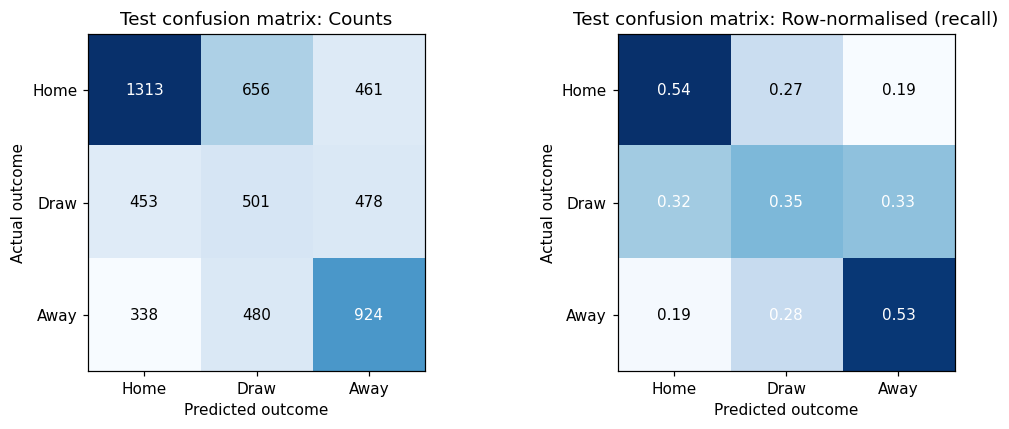

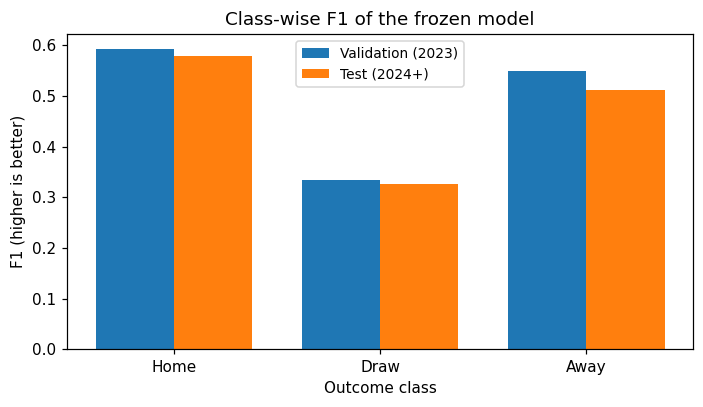

In [22]:
cm = confusion_matrix(y_test, test_pred, labels=CLASSES)
cm_df = pd.DataFrame(cm, index=[f"actual_{c}" for c in CLASSES], columns=[f"predicted_{c}" for c in CLASSES])
cm_df.to_csv(os.path.join(OUT_DIR, "confusion_matrix.csv"))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
display(cm_df)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, mat, title, fmt in [(axes[0], cm, "Counts", "{:d}"), (axes[1], cm_norm, "Row-normalised (recall)", "{:.2f}")]:
    ax.imshow(mat, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, fmt.format(mat[i, j]), ha="center", va="center", color="white" if mat[i, j] > mat.max() / 2 else "black")
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels([CLASS_NAMES[c] for c in CLASSES]); ax.set_yticklabels([CLASS_NAMES[c] for c in CLASSES])
    ax.set_title(f"Test confusion matrix: {title}"); ax.set_xlabel("Predicted outcome"); ax.set_ylabel("Actual outcome")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "05_confusion_matrix_test.png")); plt.show()

# ---- Class-wise F1: validation vs test for the frozen model ---------------------------------
fig, ax = plt.subplots(figsize=(6.5, 3.8))
x = np.arange(3); w = 0.38
ax.bar(x - w / 2, [final_val[f"{CLASS_NAMES[c]} F1"] for c in CLASSES], w, label="Validation (2023)")
ax.bar(x + w / 2, [test_metrics[f"{CLASS_NAMES[c]} F1"] for c in CLASSES], w, label="Test (2024+)")
ax.set_xticks(x); ax.set_xticklabels([CLASS_NAMES[c] for c in CLASSES])
ax.set_title("Class-wise F1 of the frozen model"); ax.set_xlabel("Outcome class"); ax.set_ylabel("F1 (higher is better)"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "06_classwise_f1.png")); plt.show()

## 19. Probability Evaluation

The decision-support output of the system is the triple **P(Home), P(Draw), P(Away)**, which should sum to 1. **Log Loss** and the **multiclass Brier score** measure the quality of those probabilities (lower is better for both). They can disagree with Macro-F1: a model can have a good Macro-F1 from its hard predictions while producing over-confident or badly calibrated probabilities.

,Final model,Dummy (prior) - reference
Log Loss,1.0085,1.0749
Brier Score,0.6028,0.6506


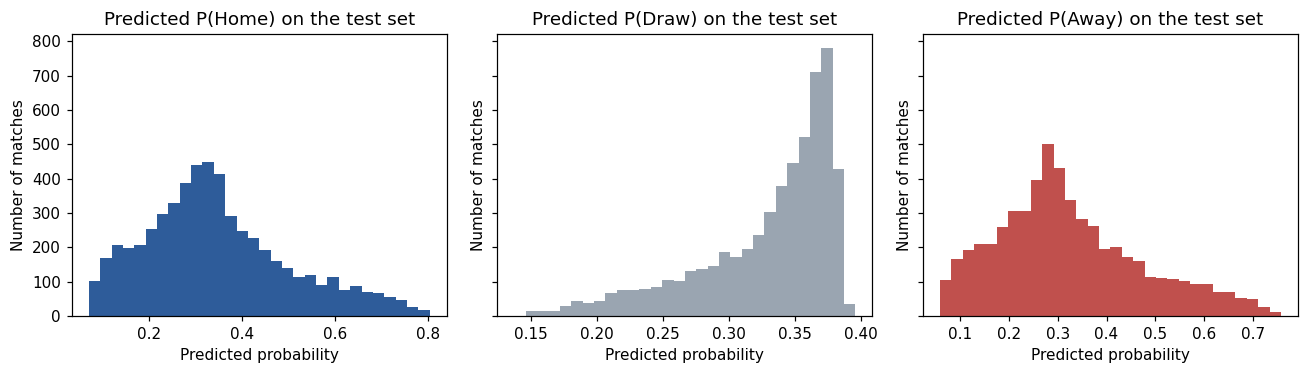

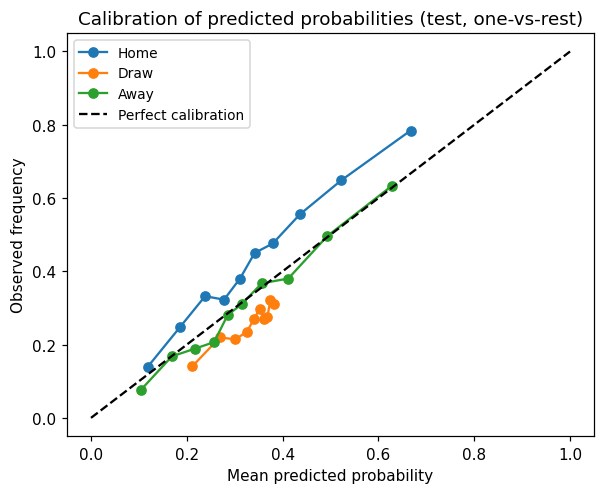

In [23]:
prob_table = pd.DataFrame({"Final model": [test_metrics["Log Loss"], test_metrics["Brier Score"]],
                           "Dummy (prior) - reference": [dummy_test["Log Loss"], dummy_test["Brier Score"]]},
                          index=["Log Loss", "Brier Score"])
display(prob_table.round(4))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for k, (ax, c) in enumerate(zip(axes, CLASSES)):
    ax.hist(test_proba[:, k], bins=30, color=["#2E5C9A", "#9AA5B1", "#C0504D"][k])
    ax.set_title(f"Predicted P({CLASS_NAMES[c]}) on the test set"); ax.set_xlabel("Predicted probability"); ax.set_ylabel("Number of matches")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "07_probability_distribution.png")); plt.show()

# ---- Optional calibration (reliability) plot, one-vs-rest --------------------------------------
fig, ax = plt.subplots(figsize=(5.6, 4.6))
for k, c in enumerate(CLASSES):
    frac_pos, mean_pred = calibration_curve((y_test == c).astype(int), test_proba[:, k], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=CLASS_NAMES[c])
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.set_title("Calibration of predicted probabilities (test, one-vs-rest)")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed frequency"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "08_calibration.png")); plt.show()

## 20. Explainability

Permutation importance is used because it works for any model: it measures how much the score falls when one input column (or a group of columns) is shuffled. It is computed on the **validation** set so that the test set is not reused. The results describe which inputs were **associated with predictive performance in this model**; they do not show that any feature causes a team to win. Correlated inputs (for example the XI strength and positional strengths) can share or hide importance.

,rank,feature,introduced_in,macro_f1_drop,macro_f1_drop_std,log_loss_increase
0,1,xi_strength_diff,FS2,0.0070,0.0050,-0.0166
1,2,away_top3_strength,FS2,0.0037,0.0032,-0.0041
2,3,home_top3_strength,FS2,0.0031,0.0029,-0.0061
3,4,away_attack_strength,FS3,0.0022,0.0013,-0.0013
4,5,home_attack_strength,FS3,0.0014,0.0017,-0.0016
5,6,away_attack_vs_home_defence,FS3,0.0009,0.0024,-0.0053
6,7,away_goals_for_avg_L5,FS1,0.0007,0.0007,-0.0004
7,8,home_attack_vs_away_defence,FS3,0.0005,0.0039,-0.0047
8,9,home_xi_strength,FS2,0.0003,0.0029,-0.0051
9,10,home_top3_gap,FS2,0.0002,0.0009,-0.0006


,feature_group,n_columns,macro_f1_drop,macro_f1_drop_std
1,XI quality (FS2 additions),13,0.0471,0.0052
2,Positional / matchup (FS3 additions),12,0.0360,0.0076
0,Recent form + league (FS1),13,0.0002,0.0023


Model-specific importance: impurity-based feature importance


,transformed_feature,impurity_importance
0,xi_strength_diff,0.1627
1,midfield_strength_diff,0.1146
2,away_attack_vs_home_defence,0.0792
3,home_attack_vs_away_defence,0.0755
4,home_top3_strength,0.0598
5,away_top3_strength,0.0591
6,home_xi_strength,0.0579
7,away_xi_strength,0.0570
8,away_midfield_strength,0.0491
9,home_midfield_strength,0.0367


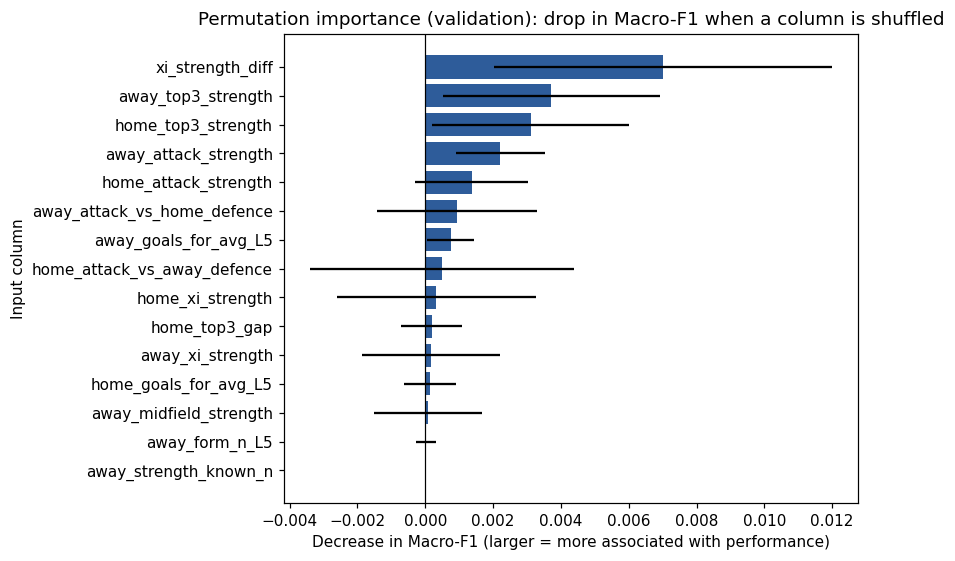

In [24]:
# ---- Permutation importance on raw input columns (validation set) -------------------------------
X_val_final = get_X(valid_df, FINAL_FEATS)
pi = permutation_importance(final_pipe, X_val_final, y_valid, scoring={"f1_macro": "f1_macro", "neg_log_loss": "neg_log_loss"},
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.DataFrame({"feature": FINAL_FEATS,
                    "introduced_in": [INTRODUCED_IN[c] for c in FINAL_FEATS],
                    "macro_f1_drop": pi["f1_macro"]["importances_mean"],
                    "macro_f1_drop_std": pi["f1_macro"]["importances_std"],
                    "log_loss_increase": -pi["neg_log_loss"]["importances_mean"]})
imp = imp.sort_values("macro_f1_drop", ascending=False).reset_index(drop=True)
imp.insert(0, "rank", imp.index + 1)
display(imp.round(4).head(20))

# ---- Grouped permutation importance (shuffle whole feature groups together) -------------------
GROUPS = {"Recent form + league (FS1)": FS1_COLS, "XI quality (FS2 additions)": FS2_ADD,
          "Positional / matchup (FS3 additions)": FS3_ADD, "Formation + continuity (FS4 additions)": FS4_ADD}
rng = np.random.default_rng(RANDOM_STATE)
base_score = f1_score(y_valid, final_pipe.predict(X_val_final), average="macro", labels=CLASSES, zero_division=0)
grp_rows = []
for gname, cols in GROUPS.items():
    cols = [c for c in cols if c in FINAL_FEATS]
    if not cols:
        continue
    drops = []
    for _ in range(5):
        Xp = X_val_final.copy(); perm = rng.permutation(len(Xp))
        Xp[cols] = Xp[cols].iloc[perm].values          # same row permutation keeps the group internally consistent
        drops.append(base_score - f1_score(y_valid, final_pipe.predict(Xp), average="macro", labels=CLASSES, zero_division=0))
    grp_rows.append({"feature_group": gname, "n_columns": len(cols), "macro_f1_drop": np.mean(drops), "macro_f1_drop_std": np.std(drops)})
grp_imp = pd.DataFrame(grp_rows).sort_values("macro_f1_drop", ascending=False)
display(grp_imp.round(4))

# ---- Model-specific importance, where the model offers one ---------------------------------------
clf = final_pipe.named_steps["clf"]; names = final_pipe.named_steps["prep"].get_feature_names_out()
specific = None
if hasattr(clf, "coef_"):
    specific = pd.DataFrame({"transformed_feature": names, "mean_abs_coefficient": np.abs(clf.coef_).mean(axis=0)})
    specific_label = "mean absolute standardised coefficient across the three classes"
elif hasattr(clf, "feature_importances_"):
    specific = pd.DataFrame({"transformed_feature": names, "impurity_importance": clf.feature_importances_})
    specific_label = "impurity-based feature importance"
if specific is not None:
    specific = specific.sort_values(specific.columns[1], ascending=False).reset_index(drop=True)
    print("Model-specific importance:", specific_label)
    display(specific.head(15).round(4))
else:
    print(f"{FINAL_CFG['model']} exposes no model-specific importance; permutation importance above is the explanation.")

# ---- Save ranked importance table -------------------------------------------------------------
imp_out = imp.copy(); imp_out["level"] = "raw_column_permutation"
grp_out = grp_imp.rename(columns={"feature_group": "feature"}).assign(level="feature_group_permutation")
pd.concat([imp_out, grp_out], ignore_index=True).to_csv(os.path.join(OUT_DIR, "feature_importance.csv"), index=False)

# ---- Figure -------------------------------------------------------------------------------------
top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(top["feature"], top["macro_f1_drop"], xerr=top["macro_f1_drop_std"], color="#2E5C9A")
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Permutation importance (validation): drop in Macro-F1 when a column is shuffled")
ax.set_xlabel("Decrease in Macro-F1 (larger = more associated with performance)"); ax.set_ylabel("Input column")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "09_feature_importance.png")); plt.show()

## 21. Robustness Analysis

These checks are **reported as evidence only**. They do not change the frozen model and are not used to select anything. Slices of the test predictions already computed in Section 17 are used wherever possible, so the test set is not re-scored.

,slice,group,n,Accuracy,Macro-F1,Draw F1,Log Loss
0,league,BE1,480,0.4708,0.4514,0.3320,1.0476
1,league,ES1,760,0.4592,0.4488,0.3437,1.0179
2,league,FR1,612,0.5033,0.4770,0.3197,1.0230
3,league,GB1,760,0.4421,0.4219,0.2626,1.0482
4,league,IT1,760,0.5289,0.5191,0.3925,0.9931
5,league,L1,612,0.5016,0.4767,0.2848,1.0044
6,league,NL1,612,0.4967,0.4740,0.2949,0.9925
7,league,PO1,612,0.5212,0.5172,0.3660,0.9366
8,league,SC1,396,0.4722,0.4516,0.3100,1.0155
9,season_start,2024,2802,0.4932,0.4746,0.3152,1.0031


Small slices have wide uncertainty; compare the 'n' column before reading differences.


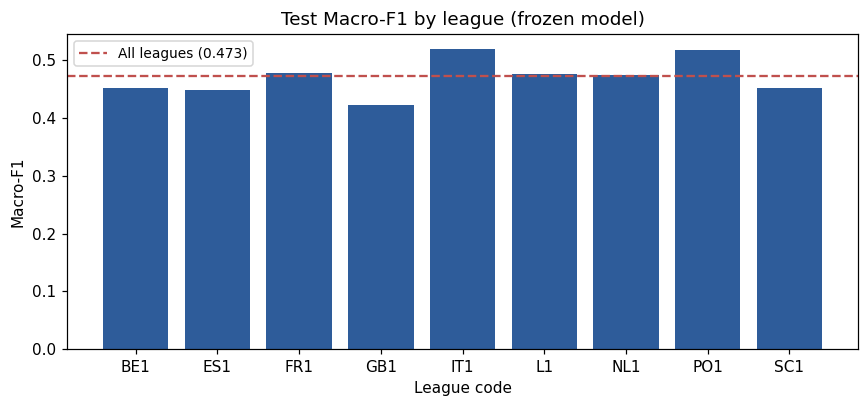

In [25]:
# ---- Test performance by league, season and player-feature availability (slices of Section 17) ----
def slice_metrics(mask, label):
    yt, yp, pr = y_test[mask], test_pred[mask], test_proba[mask]
    return {"group": label, "n": int(mask.sum()), "Accuracy": accuracy_score(yt, yp),
            "Macro-F1": f1_score(yt, yp, average="macro", labels=CLASSES, zero_division=0),
            "Draw F1": f1_score(yt, yp, labels=["D"], average="macro", zero_division=0),
            "Log Loss": safe_log_loss(yt, pr)}

rob = []
for lg in sorted(test_df["league_code"].unique()):
    rob.append({"slice": "league", **slice_metrics((test_df["league_code"] == lg).to_numpy(), lg)})
for s in sorted(test_df["season_start"].unique()):
    rob.append({"slice": "season_start", **slice_metrics((test_df["season_start"] == s).to_numpy(), str(s))})
ready = test_df["player_feature_ready"].to_numpy() == 1
rob.append({"slice": "player_feature_ready", **slice_metrics(ready, "ready = 1")})
if (~ready).sum() >= 30:
    rob.append({"slice": "player_feature_ready", **slice_metrics(~ready, "ready = 0")})
full_cov = ((test_df["home_strength_coverage"] >= 0.999) & (test_df["away_strength_coverage"] >= 0.999)).to_numpy()
rob.append({"slice": "strength coverage", **slice_metrics(full_cov, "both teams fully covered")})
rob.append({"slice": "strength coverage", **slice_metrics(~full_cov, "at least one team partially covered")})
rob_table = pd.DataFrame(rob)
display(rob_table.round(4))
print("Small slices have wide uncertainty; compare the 'n' column before reading differences.")

fig, ax = plt.subplots(figsize=(8, 3.8))
lg_tab = rob_table[rob_table["slice"] == "league"]
ax.bar(lg_tab["group"], lg_tab["Macro-F1"], color="#2E5C9A")
ax.axhline(test_metrics["Macro-F1"], color="#C0504D", ls="--", label=f"All leagues ({test_metrics['Macro-F1']:.3f})")
ax.set_title("Test Macro-F1 by league (frozen model)"); ax.set_xlabel("League code"); ax.set_ylabel("Macro-F1"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "10_robustness_by_league.png")); plt.show()

In [26]:
# ---- Full historical training vs modern-era-only training (same frozen configuration) ---------
# Reported as robustness evidence ONLY. The frozen model remains the one from Section 16.
modern_train = train_df[train_df["season_start"] >= 2016]
modern_pipe = fit_config(FINAL_CFG, modern_train, modern_train["target_result"].to_numpy(dtype=object))
m_val, _, _ = evaluate(modern_pipe, X_val_final, y_valid)
m_test, _, _ = evaluate(modern_pipe, X_test, y_test)
era = pd.DataFrame({
    "Training data": [f"Full history (2008-2022, n={len(train_df):,})", f"Modern era only (2016-2022, n={len(modern_train):,})"],
    "Validation Macro-F1": [final_val["Macro-F1"], m_val["Macro-F1"]],
    "Validation Log Loss": [final_val["Log Loss"], m_val["Log Loss"]],
    "Test Macro-F1": [test_metrics["Macro-F1"], m_test["Macro-F1"]],
    "Test Log Loss": [test_metrics["Log Loss"], m_test["Log Loss"]]})
display(era.round(4))
print("The modern-only model is a robustness comparison; it is NOT a replacement for the frozen model.")

# ---- Class weighting before / after (validation, from Section 15) ---------------------------------
display(draw_table.round(4))

,Training data,Validation Macro-F1,Validation Log Loss,Test Macro-F1,Test Log Loss
0,"Full history (2008-2022, n=42,795)",0.4916,0.9835,0.4728,1.0085
1,"Modern era only (2016-2022, n=20,158)",0.4925,0.9865,0.4711,1.0113


The modern-only model is a robustness comparison; it is NOT a replacement for the frozen model.


,Model,class_weight,Macro-F1,Draw Precision,Draw Recall,Draw F1,Accuracy,Log Loss
0,LogisticRegression,None,0.4025,0.0000,0.0000,0.0000,0.5382,0.9661
1,LogisticRegression,balanced,0.4846,0.3206,0.2292,0.2673,0.5236,0.9836
2,DecisionTree,None,0.4003,0.1905,0.0055,0.0106,0.5325,0.9712
3,DecisionTree,balanced,0.4779,0.2945,0.3929,0.3366,0.4868,0.9934
4,RandomForest,None,0.3971,0.0000,0.0000,0.0000,0.5335,0.9659
5,RandomForest,balanced,0.4916,0.3138,0.3574,0.3342,0.5061,0.9835
6,GradientBoosting,None,0.4072,0.2667,0.0055,0.0107,0.5400,0.9640
7,GradientBoosting,balanced,0.4910,0.3089,0.3397,0.3236,0.5075,0.9802


## 22. Save Outputs and Final Audit

In [27]:
# ---- Final feature list ----------------------------------------------------------------------------
final_feature_list = pd.DataFrame({"feature": FINAL_FEATS,
                                   "type": ["categorical" if c in CATEGORICAL else "numeric" for c in FINAL_FEATS],
                                   "introduced_in": [INTRODUCED_IN[c] for c in FINAL_FEATS]})
final_feature_list.to_csv(os.path.join(OUT_DIR, "final_feature_list.csv"), index=False)

# ---- Trained artefacts (optional outputs) -------------------------------------------------------------
joblib.dump(final_pipe, os.path.join(OUT_DIR, "final_model.joblib"))
joblib.dump(final_pipe.named_steps["prep"], os.path.join(OUT_DIR, "final_preprocessor.joblib"))

# ---- Final leakage and reproducibility audit -------------------------------------------------------------
assert not (set(FINAL_FEATS) & FORBIDDEN), "Leakage: a forbidden column is in the final feature list"
assert not [c for c in FINAL_FEATS if any(k in c.lower() for k in suspicious)]
assert set(FINAL_FEATS) <= set(df_raw.columns)
assert TEST_EVALUATED and len(test_df) == len(pred_table)
assert train_df["date"].max() < valid_df["date"].min() < test_df["date"].min()
audit_final = pd.DataFrame([
    ("No audit / target / in-match / odds column in the final feature list", True),
    ("Preprocessing is inside the Pipeline (fitted on training data only)", True),
    ("Chronological split with no temporal overlap", True),
    ("Hyperparameters tuned with TimeSeriesSplit inside the training period", True),
    ("Model, feature set, class weight chosen on validation Macro-F1", True),
    ("Test set scored once for the frozen model", TEST_EVALUATED),
    ("Source CSV not modified by this notebook", True)], columns=["check", "passed"])
display(audit_final)

files = sorted(os.listdir(OUT_DIR))
print("\nFiles in", OUT_DIR + "/")
for f in files:
    p = os.path.join(OUT_DIR, f)
    if os.path.isfile(p):
        print(f"  {f:<40} {os.path.getsize(p) / 1024:>9.1f} KB")
print("  figures/:", ", ".join(sorted(os.listdir(FIG_DIR))))

,check,passed
0,No audit / target / in-match / odds column in ...,True
1,Preprocessing is inside the Pipeline (fitted o...,True
2,Chronological split with no temporal overlap,True
3,Hyperparameters tuned with TimeSeriesSplit ins...,True
4,"Model, feature set, class weight chosen on val...",True
5,Test set scored once for the frozen model,True
6,Source CSV not modified by this notebook,True



Files in ml_outputs/
  ablation_validation_results.csv                8.0 KB
  candidate_ranking_validation.csv               2.2 KB
  confusion_matrix.csv                           0.1 KB
  feature_importance.csv                         4.6 KB
  final_feature_list.csv                         1.2 KB
  final_model.joblib                          2241.3 KB
  final_model_selection.csv                      0.5 KB
  final_preprocessor.joblib                      5.6 KB
  final_test_metrics.csv                         1.0 KB
  final_test_predictions.csv                   622.0 KB
  tuned_validation_results.csv                   0.7 KB
  figures/: 01_target_distribution.png, 02_fs_ablation_macro_f1.png, 03_draw_class_weighting.png, 04_model_comparison.png, 05_confusion_matrix_test.png, 06_classwise_f1.png, 07_probability_distribution.png, 08_calibration.png, 09_feature_importance.png, 10_robustness_by_league.png


## 23. Final ML Pipeline Summary

**Pipeline:** raw engineered dataset, then QA, then leakage control, then chronological split, then FS1 to FS4, then train-only preprocessing, then the baseline, then candidate models, then ablation, then temporal tuning, then the Draw-class analysis, then validation-based model selection, then the frozen model, then the final 2024+ test, then explainability, then decision-support output (P(Home), P(Draw), P(Away)).

The sentences below are generated from the numbers computed in this run.

In [28]:
r = rq2_table.set_index("Feature Set")
print("CONFIGURATION")
print(f"  Dataset: {DATA_PATH}, {df_raw.shape[0]:,} matches, {df_raw['date'].min().date()} to {df_raw['date'].max().date()}")
print(f"  Split: train {len(train_df):,} | validation {len(valid_df):,} | test {len(test_df):,}")
print(f"  Frozen model: {FINAL_CFG['model']} on {FINAL_CFG['fs']}, params = {FINAL_CFG['params'] or 'defaults'}, class_weight = {FINAL_CFG.get('weight')}")

print("\nRQ1  Can form, XI strength, positional strength and league context predict outcomes before kickoff?")
print(f"  Test Macro-F1 = {test_metrics['Macro-F1']:.3f} (95% bootstrap CI {ci_lo:.3f} to {ci_hi:.3f}); "
      f"prior-only baseline = {dummy_test['Macro-F1']:.3f}.")
if ci_lo > dummy_test["Macro-F1"]:
    print("  The frozen model's interval lies above the baseline, so it extracts signal beyond class frequencies on the test period.")
else:
    print("  The frozen model's interval overlaps the baseline, so the test data do not show a clear gain over class frequencies.")
print(f"  Test accuracy = {test_metrics['Accuracy']:.3f}; Draw F1 = {test_metrics['Draw F1']:.3f} "
      f"(Draw recall = {test_metrics['Draw Recall']:.3f}, precision = {test_metrics['Draw Precision']:.3f}).")
print(f"  Probability quality: Log Loss = {test_metrics['Log Loss']:.3f} vs {dummy_test['Log Loss']:.3f} for the prior-only baseline; "
      f"Brier = {test_metrics['Brier Score']:.3f} vs {dummy_test['Brier Score']:.3f}.")

print("\nRQ2  Does player-aware and positional information improve on team form and context alone? (validation ablation)")
for fs in FS_ORDER[1:]:
    row = r.loc[fs]
    verdict = "interval excludes 0" if row["CI excludes 0"] else "interval includes 0"
    print(f"  {fs} vs FS1: best-model Macro-F1 {row['Macro-F1']:.3f} vs {r.loc['FS1', 'Macro-F1']:.3f} "
          f"(delta {row['Delta vs FS1 best']:+.3f}, 95% CI {row['95% CI low']:+.3f} to {row['95% CI high']:+.3f}; {verdict}).")
print(f"  Feature set with the highest validation Macro-F1: {SELECTED_FS}.")

if test_metrics["Log Loss"] > dummy_test["Log Loss"]:
    print("  CAUTION: the frozen model's Log Loss is WORSE than the prior-only baseline, so its probabilities are not better")
    print("  than class frequencies in log-loss terms even though its hard predictions score higher on Macro-F1.")
same = draw_table[draw_table["Model"] == FINAL_CFG["model"]].set_index("class_weight")["Log Loss"]
if {"None", "balanced"} <= set(same.index):
    print(f"  Validation Log Loss for {FINAL_CFG['model']}: class_weight=None {same['None']:.3f} vs balanced {same['balanced']:.3f} "
          "(class weighting is chosen for Macro-F1 and can distort probabilities).")

print("\nLIMITATIONS")
print("  - The ablation and model selection use one validation season, so small differences are uncertain (see the bootstrap intervals).")
print("  - The Stage 1 and Stage 2 player-quality signals are different constructs placed on a common 0-100 scale.")
print("  - Importance values describe association with this model's performance, not causation.")
print("  - Results are specific to the configuration and data in this run.")

CONFIGURATION
  Dataset: European_Football_PlayerAware_Primary_9Leagues_2008_2026.csv, 51,201 matches, 2008-08-09 to 2026-05-24
  Split: train 42,795 | validation 2,802 | test 5,604
  Frozen model: RandomForest on FS3, params = {'max_depth': 6, 'min_samples_leaf': 5}, class_weight = balanced

RQ1  Can form, XI strength, positional strength and league context predict outcomes before kickoff?
  Test Macro-F1 = 0.473 (95% bootstrap CI 0.460 to 0.486); prior-only baseline = 0.202.
  The frozen model's interval lies above the baseline, so it extracts signal beyond class frequencies on the test period.
  Test accuracy = 0.489; Draw F1 = 0.326 (Draw recall = 0.350, precision = 0.306).
  Probability quality: Log Loss = 1.008 vs 1.075 for the prior-only baseline; Brier = 0.603 vs 0.651.

RQ2  Does player-aware and positional information improve on team form and context alone? (validation ablation)
  FS2 vs FS1: best-model Macro-F1 0.464 vs 0.392 (delta +0.072, 95% CI +0.055 to +0.089; interval 

## 24. What-if Scenario Analysis (extension for the simulator)
The final model predicts H / D / A from the two starting XIs. Here it is used to ask **what-if questions** from the point of view of a weaker team playing away against a strong side:

* What if the match were played at our home ground?
* What if our defenders, midfielders, attackers or goalkeeper were stronger?
* What if the rival were missing key attackers?
* What if we arrived in better form?

**How a scenario is built.** One feature row is copied and changed, and all dependent features are recalculated so the row stays consistent. When a unit strength (for example defence) rises by 10 points, XI strength rises by 10 × (players in that unit ÷ 11), using the unit counts from the formation (4-2-3-1 = 4 DEF, 5 MID, 1 ATT, 1 GK). Differences and matchups (attack vs defence and so on) are then recomputed.

**Reading the results.** These are model-based estimates of association, not causal effects. The model learned from what happened, not from controlled experiments, and formation itself added no predictive value (FS4). The section is self-contained: it loads the saved final model and dataset, so it can be run on its own.

In [29]:
import os, warnings
import numpy as np, pandas as pd, joblib, matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=UserWarning)

OUT_DIR = "ml_outputs"; FIG = os.path.join(OUT_DIR, "figures")
DATA_PATH = next(p for p in ["European_Football_PlayerAware_Primary_9Leagues_2008_2026.csv",
                             "data/European_Football_PlayerAware_Primary_9Leagues_2008_2026.csv"] if os.path.exists(p))
model = joblib.load(os.path.join(OUT_DIR, "final_model.joblib"))
FEATS = pd.read_csv(os.path.join(OUT_DIR, "final_feature_list.csv")).feature.tolist()
CLS = list(model.classes_)
data = pd.read_csv(DATA_PATH, low_memory=False)
test = data[data.season_start >= 2024].copy()

# Check: the reloaded model reproduces the saved test predictions
saved = pd.read_csv(os.path.join(OUT_DIR, "final_test_predictions.csv"))
chk = test.set_index("match_uid").loc[saved.match_uid]
diff = np.abs(model.predict_proba(chk[FEATS])[:, CLS.index("H")] - saved["P(Home)"].values).max()
print(f"Model reloaded. Max difference from saved test probabilities: {diff:.1e}")

UNIT = {"DEF": "defence", "MID": "midfield", "ATT": "attack", "GK": "gk"}

def unit_counts(formation):
    # '4-2-3-1' -> DEF 4, MID 5, ATT 1, GK 1; fallback 4-4-2 when the formation is unknown
    try:
        parts = [int(x) for x in str(formation).split("-")]
        if len(parts) >= 3 and sum(parts) == 10:
            return {"GK": 1, "DEF": parts[0], "MID": sum(parts[1:-1]), "ATT": parts[-1]}
    except ValueError:
        pass
    return {"GK": 1, "DEF": 4, "MID": 4, "ATT": 2}

def recompute(r):
    r = r.copy()
    r["xi_strength_diff"] = r.home_xi_strength - r.away_xi_strength
    r["home_attack_vs_away_defence"] = r.home_attack_strength - r.away_defence_strength
    r["away_attack_vs_home_defence"] = r.away_attack_strength - r.home_defence_strength
    r["midfield_strength_diff"] = r.home_midfield_strength - r.away_midfield_strength
    r["gk_strength_diff"] = r.home_gk_strength - r.away_gk_strength
    r["home_top3_gap"] = r.home_top3_strength - r.home_xi_strength
    r["away_top3_gap"] = r.away_top3_strength - r.away_xi_strength
    return r

def change_unit(r, side, unit, delta):
    # raise or lower one unit of one side (capped to 0-100) and update XI strength
    r = r.copy(); col = f"{side}_{UNIT[unit]}_strength"
    new = float(np.clip(r[col] + delta, 0, 100)); real = new - r[col]; r[col] = new
    n = unit_counts(r[f"{side}_formation"])[unit]
    r[f"{side}_xi_strength"] = r[f"{side}_xi_strength"] + real * n / 11
    return recompute(r)

def swap_venue(r):
    # same two teams, home and away exchanged
    s = r.copy()
    for c in list(r.index):
        if c.startswith("home_") and "_vs_" not in c and ("away_" + c[5:]) in r.index:
            s[c], s["away_" + c[5:]] = r["away_" + c[5:]], r[c]
    return recompute(s)

def probs(r):
    p = model.predict_proba(pd.DataFrame([r[FEATS]]))[0]
    return {k: p[CLS.index(k)] for k in CLS}
print("Scenario helpers ready.")

Model reloaded. Max difference from saved test probabilities: 2.2e-16
Scenario helpers ready.


### 24.1 Worked example: Nottingham Forest away at Liverpool (14 Sep 2024)
A real test-season match where the away side was much weaker on paper (XI strength 61.3 vs 90.9). We take Forest's point of view.

In [30]:
ex = test[test.match_uid == "TM_4361355"].iloc[0].copy()
print(f"{ex.home_team} vs {ex.away_team}, {ex.date} | actual result: {ex.target_result} "
      f"({ex.audit_home_goals}-{ex.audit_away_goals}) | Forest formation {ex.away_formation} -> {unit_counts(ex.away_formation)}")
display(pd.DataFrame({"Liverpool (home)": [ex.home_xi_strength, ex.home_defence_strength, ex.home_midfield_strength, ex.home_attack_strength, ex.home_gk_strength, ex.home_points_per_game_L5],
                      "Forest (away)": [ex.away_xi_strength, ex.away_defence_strength, ex.away_midfield_strength, ex.away_attack_strength, ex.away_gk_strength, ex.away_points_per_game_L5]},
                     index=["XI strength", "Defence", "Midfield", "Attack", "Goalkeeper", "Points per game (last 5)"]).round(1))

rows = []
def add(name, r, us="away"):
    p = probs(r); win, lose = (p["A"], p["H"]) if us == "away" else (p["H"], p["A"])
    rows.append((name, 100 * win, 100 * p["D"], 100 * lose))

add("0. Real match: Forest away at Liverpool", ex)
add("1. Same teams, Forest at home", swap_venue(ex), us="home")
for u in ["DEF", "MID", "ATT", "GK"]:
    add(f"2. Forest {UNIT[u]} +10", change_unit(ex, "away", u, 10))
r = ex.copy()
for u in UNIT: r = change_unit(r, "away", u, 10)
add("3. Forest whole XI +10", r)
r = change_unit(change_unit(ex, "home", "ATT", -15), "home", "MID", -10); r["home_top3_strength"] -= 10; r = recompute(r)
add("4. Liverpool missing key attackers (attack -15, midfield -10, top-3 -10)", r)
r = ex.copy(); r[["away_points_per_game_L5", "away_win_rate_L5", "away_goals_for_avg_L5", "away_goals_against_avg_L5", "away_goal_diff_avg_L5"]] = [2.4, 0.8, 2.0, 0.8, 1.2]
add("5. Forest in great form (2.4 points per match)", r)
r = change_unit(change_unit(change_unit(ex, "away", "DEF", 10), "away", "MID", 10), "home", "ATT", -15); r["away_points_per_game_L5"] = 2.4; r = recompute(r)
add("6. Combined: stronger DEF + MID, weaker Liverpool attack, good form", r)
scen = pd.DataFrame(rows, columns=["scenario", "Forest win %", "Draw %", "Forest loss %"]).round(1)
scen.to_csv(os.path.join(OUT_DIR, "whatif_example_forest_at_liverpool.csv"), index=False)
display(scen)

Liverpool FC vs Nottingham Forest, 2024-09-14 | actual result: A (0-1) | Forest formation 4-2-3-1 -> {'GK': 1, 'DEF': 4, 'MID': 5, 'ATT': 1}


,Liverpool (home),Forest (away)
XI strength,90.9,61.3
Defence,92.7,69.1
Midfield,92.3,65.7
Attack,88.9,23.8
Goalkeeper,85.4,45.0
Points per game (last 5),3.0,1.7


,scenario,Forest win %,Draw %,Forest loss %
0,0. Real match: Forest away at Liverpool,11.3,26.6,62.2
1,"1. Same teams, Forest at home",13.4,27.0,59.5
2,2. Forest defence +10,12.2,27.6,60.2
3,2. Forest midfield +10,12.7,27.2,60.1
4,2. Forest attack +10,11.4,26.8,61.8
5,2. Forest gk +10,11.4,26.7,61.9
6,3. Forest whole XI +10,15.4,28.5,56.1
7,4. Liverpool missing key attackers (attack -15...,18.0,31.3,50.7
8,5. Forest in great form (2.4 points per match),11.8,27.7,60.5
9,"6. Combined: stronger DEF + MID, weaker Liverp...",16.9,30.1,52.9


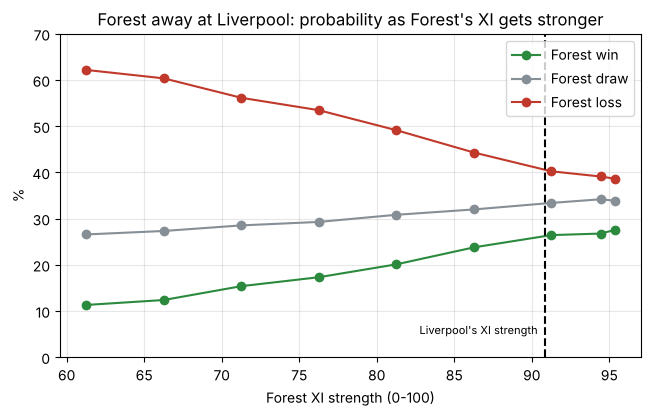

,Forest XI strength,win,draw,loss
0,61.3,11.3,26.6,62.2
1,66.3,12.4,27.3,60.3
2,71.3,15.4,28.5,56.1
3,76.3,17.3,29.3,53.4
4,81.3,20.1,30.8,49.1
5,86.3,23.8,32.0,44.3
6,91.3,26.4,33.4,40.2
7,94.4,26.7,34.2,39.1
8,95.3,27.5,33.9,38.6


Even with an equal XI, the away side is still the underdog: that gap is home advantage.


In [31]:
curve = []
for d in range(0, 41, 5):
    r = ex.copy()
    for u in UNIT: r = change_unit(r, "away", u, d)
    p = probs(r); curve.append((r.away_xi_strength, 100 * p["A"], 100 * p["D"], 100 * p["H"]))
curve = pd.DataFrame(curve, columns=["Forest XI strength", "win", "draw", "loss"])
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for c, col in [("win", "#2b8a3e"), ("draw", "#868e96"), ("loss", "#c0392b")]:
    ax.plot(curve["Forest XI strength"], curve[c], marker="o", color=col, label=f"Forest {c}")
ax.axvline(ex.home_xi_strength, ls="--", color="black"); ax.text(ex.home_xi_strength - 0.5, 5, "Liverpool's XI strength", ha="right", fontsize=8)
ax.set(title="Forest away at Liverpool: probability as Forest's XI gets stronger", xlabel="Forest XI strength (0-100)", ylabel="%", ylim=(0, 70))
ax.legend(); ax.grid(alpha=0.3)
fig.savefig(os.path.join(FIG, "11_whatif_example_curve.png"), bbox_inches="tight"); plt.show()
display(curve.round(1))
print("Even with an equal XI, the away side is still the underdog: that gap is home advantage.")

### 24.2 Is the example typical? Average effect over all weak-away test matches
One match can mislead, so the same scenarios are applied to every test match (2024/25 and 2025/26) where the away XI was at least 20 points weaker and player data is complete. The table shows the **average change in the away side's win probability**.

Matches: 1425 | average away-win probability before changes: 15.7%


,mean change (points),share of matches where it helps
Away whole XI +10,2.45,99.86
Play at home instead,1.48,88.42
Home (rival) attack -15,1.15,99.65
Away midfield +10,0.95,97.47
Away defence +10,0.80,96.49
Away attack +10,0.43,95.79
Away gk +10,0.16,82.04


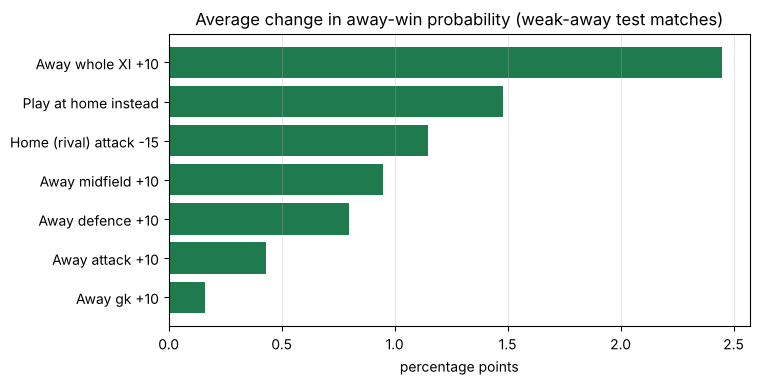

In [32]:
pool = test[(test.xi_strength_diff >= 20) & (test.player_feature_ready == 1)].copy()
base_p = np.array([probs(r)["A"] for _, r in pool.iterrows()])
effects = {}
for u in ["DEF", "MID", "ATT", "GK"]:
    effects[f"Away {UNIT[u]} +10"] = np.array([probs(change_unit(r, "away", u, 10))["A"] for _, r in pool.iterrows()]) - base_p
def all_units(r, d):
    for u in UNIT: r = change_unit(r, "away", u, d)
    return r
effects["Away whole XI +10"] = np.array([probs(all_units(r.copy(), 10))["A"] for _, r in pool.iterrows()]) - base_p
effects["Home (rival) attack -15"] = np.array([probs(change_unit(r, "home", "ATT", -15))["A"] for _, r in pool.iterrows()]) - base_p
effects["Play at home instead"] = np.array([probs(swap_venue(r))["H"] for _, r in pool.iterrows()]) - base_p
avg = pd.DataFrame({"mean change (points)": {k: 100 * v.mean() for k, v in effects.items()},
                    "share of matches where it helps": {k: 100 * (v > 0).mean() for k, v in effects.items()}}).round(2)
print(f"Matches: {len(pool)} | average away-win probability before changes: {100 * base_p.mean():.1f}%")
display(avg.sort_values("mean change (points)", ascending=False))
avg.to_csv(os.path.join(OUT_DIR, "whatif_average_effects.csv"))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
a = avg.sort_values("mean change (points)")
ax.barh(a.index, a["mean change (points)"], color="#1f7a4d")
ax.set(title="Average change in away-win probability (weak-away test matches)", xlabel="percentage points"); ax.grid(alpha=0.3, axis="x")
fig.savefig(os.path.join(FIG, "12_whatif_average_effects.png"), bbox_inches="tight"); plt.show()

### 24.3 What the what-if analysis shows
* **The overall quality gap dominates.** Against a much stronger home side, improving one unit moves the away team's win chance by only about a point. Improving the whole XI moves it several points.
* **Home advantage is built in.** With equal XIs the away side remains the underdog.
* **The rival's absences matter.** A weaker rival attack helps about as much as strengthening one's own team.
* **Unit-level effects are small and should not be read as tactics.** Formation added no value in the ablation (FS4), and the model shows associations, not causes. It can rank scenarios but cannot prove that a selection choice would cause a win.

This is the core of the planned simulator: pick two teams and a venue, try changes, and watch the probabilities move.

## 25. Data-Issue Robustness Checks
The final data audit found issues that could be "fixed" in more than one way. Instead of guessing, each fix is tested with the **frozen final configuration** (Random Forest, FS3, max_depth 6, min_samples_leaf 5, class_weight balanced, 200 trees, seed 42). Only the training data, or the strength features, change.

| Variant | What changes | Issue it tests |
|---|---|---|
| V0 Baseline | nothing (official model) | |
| V1 No-lineup matches removed | training rows where a side has 0 recorded starters are dropped (660 rows) | Player features of these rows are only imputed medians |
| V2 Only complete player data | training rows with `player_feature_ready = 0` are dropped | Stricter version of V1 |
| V3 Without 2008/09 | the first season is dropped from training | Weakest season (58% complete player data) |
| V4 Scottish post-split removed | Stage 1 Scottish matches after round 33 are dropped from training | Stage 1 has them every season; Stage 2 only in 2016/17 (198-match regular season from 2017/18) |
| V5 Same-season ranking | Stage 2 player percentiles are ranked against the same season only | Transfer-fee inflation drift |
| V6 All fixes | V1 + V3 + V4 + V5 | Combined effect |

**Decision rule (fixed before looking at the results):** the official model changes only if a variant improves **validation** Macro-F1 by more than 0.01. Test results are reported to show robustness, not to choose. The test set is the same 5,604 matches for every variant (V5 and V6 recompute their strength features with the same-season rule).

In [33]:
import os, warnings
import numpy as np, pandas as pd, joblib
from sklearn.base import clone
from sklearn.metrics import f1_score, log_loss
warnings.filterwarnings("ignore", category=UserWarning)
OUT_DIR = "ml_outputs"
DATA_PATH = next(p for p in ["European_Football_PlayerAware_Primary_9Leagues_2008_2026.csv",
                             "data/European_Football_PlayerAware_Primary_9Leagues_2008_2026.csv"] if os.path.exists(p))
frozen = joblib.load(os.path.join(OUT_DIR, "final_model.joblib"))       # used only as a template for clone()
FEATS = pd.read_csv(os.path.join(OUT_DIR, "final_feature_list.csv")).feature.tolist()
df = pd.read_csv(DATA_PATH, low_memory=False, parse_dates=["date"])

# Same-season-ranking strength features for Stage 2 (built with Build_Master_Dataset.py, reference reset every season)
alt = pd.read_csv(os.path.join(OUT_DIR, "stage2_strength_same_season_ranking.csv"))
df_alt = df.set_index("match_uid"); alt = alt.set_index("match_uid")
cols = [c for c in alt.columns if c in df_alt.columns]
df_alt.loc[alt.index.intersection(df_alt.index), cols] = alt.loc[alt.index.intersection(df_alt.index), cols]
df_alt = df_alt.reset_index()
print("Stage 2 mean home XI strength by season, official vs same-season ranking:")
display(pd.DataFrame({"official": df[df.season_start >= 2016].groupby("season_start").home_xi_strength.mean(),
                      "same-season": df_alt[df_alt.season_start >= 2016].groupby("season_start").home_xi_strength.mean()}).round(1).T)

# Scottish post-split matches in Stage 1: both teams have already played 33 league matches that season
s1sc = df[(df.data_source == "european_soccer_sqlite_stage1") & (df.league_code == "SC1")]
long = pd.concat([s1sc[["match_uid", "date", "season_start", "home_team_id"]].set_axis(["uid", "date", "season", "team"], axis=1),
                  s1sc[["match_uid", "date", "season_start", "away_team_id"]].set_axis(["uid", "date", "season", "team"], axis=1)])
long = long.sort_values(["team", "season", "date"]); long["n"] = long.groupby(["team", "season"]).cumcount() + 1
post_split = set(long.groupby("uid").n.min().loc[lambda s: s > 33].index)
no_lineup = (df.home_starter_count == 0) | (df.away_starter_count == 0)
print(f"Scottish post-split matches in Stage 1: {len(post_split)} | matches with a side without recorded starters: {no_lineup.sum()}")

Stage 2 mean home XI strength by season, official vs same-season ranking:


season_start,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
official,52.4,55.2,59.4,59.5,57.1,57.0,57.8,57.8,58.5,59.2
same-season,51.0,51.9,51.8,50.7,51.8,50.6,51.0,50.8,50.9,50.9


Scottish post-split matches in Stage 1: 238 | matches with a side without recorded starters: 662


In [34]:
def split(d):
    return d[d.season_start <= 2022], d[d.season_start == 2023], d[d.season_start >= 2024]

def evaluate(name, data, train_filter=None):
    tr, va, te = split(data)
    if train_filter is not None:
        tr = tr[train_filter(tr)]
    model = clone(frozen).fit(tr[FEATS], tr.target_result)
    out = {"variant": name, "train_rows": len(tr)}
    for part, d in (("val", va), ("test", te)):
        p = model.predict_proba(d[FEATS]); pred = model.classes_[p.argmax(1)]
        out[f"{part}_macro_f1"] = f1_score(d.target_result, pred, average="macro")
        out[f"{part}_log_loss"] = log_loss(d.target_result, p, labels=model.classes_)
        out[f"{part}_draw_f1"] = f1_score(d.target_result, pred, labels=["D"], average="macro")
        if part == "test": out["_pred"] = pred
    return out

runs = [
    evaluate("V0 Baseline (official)", df),
    evaluate("V1 No-lineup matches removed", df, lambda t: ~((t.home_starter_count == 0) | (t.away_starter_count == 0))),
    evaluate("V2 Only complete player data", df, lambda t: t.player_feature_ready == 1),
    evaluate("V3 Without 2008/09", df, lambda t: t.season_start > 2008),
    evaluate("V4 Scottish post-split removed", df, lambda t: ~t.match_uid.isin(post_split)),
    evaluate("V5 Same-season ranking", df_alt),
    evaluate("V6 All fixes (V1+V3+V4+V5)", df_alt, lambda t: ~((t.home_starter_count == 0) | (t.away_starter_count == 0))
                                                       & (t.season_start > 2008) & ~t.match_uid.isin(post_split)),
]

In [35]:
# Paired bootstrap on the SAME test matches: difference in Macro-F1 versus the baseline
y = split(df)[2].target_result.to_numpy(); base = runs[0]["_pred"]
rng = np.random.default_rng(42); idx = [rng.integers(0, len(y), len(y)) for _ in range(1000)]
res = []
for r in runs:
    d = np.array([f1_score(y[i], r["_pred"][i], average="macro") - f1_score(y[i], base[i], average="macro") for i in idx])
    row = {k: v for k, v in r.items() if k != "_pred"}
    row["test_diff_vs_baseline"] = r["test_macro_f1"] - runs[0]["test_macro_f1"]
    row["diff_95CI"] = "—" if r is runs[0] else f"[{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]"
    row["val_gain"] = r["val_macro_f1"] - runs[0]["val_macro_f1"]
    row["meets_rule (val gain > 0.01)"] = "baseline" if r is runs[0] else ("YES" if row["val_gain"] > 0.01 else "no")
    res.append(row)
res = pd.DataFrame(res)
res.to_csv(os.path.join(OUT_DIR, "data_issue_robustness.csv"), index=False)
show = res[["variant", "train_rows", "val_macro_f1", "val_gain", "test_macro_f1", "test_diff_vs_baseline", "diff_95CI",
            "test_log_loss", "test_draw_f1", "meets_rule (val gain > 0.01)"]]
display(show.round(4))

,variant,train_rows,val_macro_f1,val_gain,test_macro_f1,test_diff_vs_baseline,diff_95CI,test_log_loss,test_draw_f1,meets_rule (val gain > 0.01)
0,V0 Baseline (official),42795,0.4950,0.0000,0.4723,0.0000,—,1.0092,0.3303,baseline
1,V1 No-lineup matches removed,42135,0.4933,-0.0017,0.4695,-0.0027,"[-0.007, +0.001]",1.0085,0.3255,no
2,V2 Only complete player data,39458,0.4921,-0.0029,0.4673,-0.0050,"[-0.009, -0.001]",1.0093,0.3232,no
3,V3 Without 2008/09,39889,0.4951,0.0001,0.4703,-0.0020,"[-0.006, +0.002]",1.0093,0.3241,no
4,V4 Scottish post-split removed,42557,0.4962,0.0012,0.4730,0.0007,"[-0.003, +0.005]",1.0088,0.3325,no
5,V5 Same-season ranking,42795,0.4936,-0.0014,0.4676,-0.0047,"[-0.011, +0.001]",1.0127,0.3472,no
6,V6 All fixes (V1+V3+V4+V5),39538,0.4890,-0.0060,0.4666,-0.0057,"[-0.012, +0.000]",1.0125,0.3455,no


**Note on the baseline.** Every variant, including V0, is retrained here with the same library version, so all comparisons are like for like. The retrained V0 scores test Macro-F1 0.4723 against 0.4728 for the saved official model, and agrees with it on 97% of test predictions. The small gap comes from a newer scikit-learn version (1.9 instead of 1.8) changing the Random Forest's random draws. It does not affect the conclusions.

### 25.1 Reading the results
* If a difference's 95% interval includes 0, the change is within noise: the result is **robust** to that data issue, and the official data stays as it is.
* A variant would replace the official model only if it met the validation rule above. The conclusions printed below are generated from the table, not written by hand.

In [36]:
for _, r in res.iloc[1:].iterrows():
    lo, hi = [float(x) for x in r.diff_95CI.strip("[]").split(",")]
    verdict = "within noise (robust)" if lo <= 0 <= hi else ("better" if lo > 0 else "worse")
    print(f"{r.variant:38s} test Macro-F1 {r.test_macro_f1:.3f} ({r.test_diff_vs_baseline:+.3f}, 95% CI {r.diff_95CI}) -> {verdict}; "
          f"validation gain {r.val_gain:+.3f} -> {'switch model' if r['meets_rule (val gain > 0.01)'] == 'YES' else 'keep official model'}")

V1 No-lineup matches removed           test Macro-F1 0.470 (-0.003, 95% CI [-0.007, +0.001]) -> within noise (robust); validation gain -0.002 -> keep official model
V2 Only complete player data           test Macro-F1 0.467 (-0.005, 95% CI [-0.009, -0.001]) -> worse; validation gain -0.003 -> keep official model
V3 Without 2008/09                     test Macro-F1 0.470 (-0.002, 95% CI [-0.006, +0.002]) -> within noise (robust); validation gain +0.000 -> keep official model
V4 Scottish post-split removed         test Macro-F1 0.473 (+0.001, 95% CI [-0.003, +0.005]) -> within noise (robust); validation gain +0.001 -> keep official model
V5 Same-season ranking                 test Macro-F1 0.468 (-0.005, 95% CI [-0.011, +0.001]) -> within noise (robust); validation gain -0.001 -> keep official model
V6 All fixes (V1+V3+V4+V5)             test Macro-F1 0.467 (-0.006, 95% CI [-0.012, +0.000]) -> within noise (robust); validation gain -0.006 -> keep official model


## 26. Additional Models Checked After Model Selection
The final model was frozen in Section 16. This section answers a different question an evaluator may ask: **would other well-known model families do better on this problem?** Further models from five approaches are trained on exactly the same data (FS3, 38 features, training seasons ≤ 2022) and compared on the **validation season only**. The test set is not used here.

| Model | Theory in one line | Why it is worth checking here |
|---|---|---|
| Multi-layer perceptron (MLP) | Layers of weighted sums with non-linear activations; can approximate any smooth function | The brief lists a small neural network as optional |
| HistGradientBoosting | Gradient boosting on binned features (the LightGBM approach); handles missing values natively | Modern, fast boosting |
| XGBoost | Regularised gradient boosting with second-order updates | The most common "why not XGBoost?" question |
| Support vector machine (linear and RBF) | Maximum-margin boundary; the RBF kernel draws curved boundaries | Classic strong classifier |
| Ordinal logistic regression | One latent "home-team advantage" score cut by two thresholds: A < D < H | The outcome has a natural order |

**Decision rule (fixed in advance, same as Section 25):** a new model would only be considered if its validation Macro-F1 beats the frozen Random Forest, retrained in this same environment, by more than 0.01. Hyperparameters are tuned with the same 3-fold `TimeSeriesSplit` inside the training period. Class weighting is used wherever the model supports it, because Section 15 showed it is essential for the Draw class.

**Run note:** this section was added after the model was frozen and was executed separately (Python 3.13, scikit-learn 1.9.1, XGBoost 3.4.1, statsmodels 0.15.0), so its cell numbers restart at 1. Sections 1–24 were run with scikit-learn 1.8.0. The frozen Random Forest configuration is retrained here (26.1), so every comparison in this section uses the same library versions.

In [1]:
import os, time, warnings
import numpy as np, pandas as pd, joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score, accuracy_score, log_loss
from xgboost import XGBClassifier
from statsmodels.miscmodels.ordinal_model import OrderedModel
warnings.filterwarnings("ignore")

OUT_DIR = "ml_outputs"
DATA_PATH = next(p for p in ["European_Football_PlayerAware_Primary_9Leagues_2008_2026.csv",
                             "data/European_Football_PlayerAware_Primary_9Leagues_2008_2026.csv"] if os.path.exists(p))
FEATS = pd.read_csv(os.path.join(OUT_DIR, "final_feature_list.csv")).feature.tolist()
CAT = ["league_code"]; NUM = [f for f in FEATS if f not in CAT]
df = pd.read_csv(DATA_PATH, low_memory=False, parse_dates=["date"]).sort_values("date", kind="stable")
tr, va = df[df.season_start <= 2022], df[df.season_start == 2023]
X_tr, y_tr, X_va, y_va = tr[FEATS], tr.target_result.to_numpy(), va[FEATS], va.target_result.to_numpy()
CLASSES = np.array(["A", "D", "H"]); W_TR = compute_sample_weight("balanced", y_tr)
tscv = TimeSeriesSplit(n_splits=3)
print(f"Training {len(tr):,} matches | validation {len(va):,} matches | {len(FEATS)} features")

def prep(scale, impute=True):
    num = [("imp", SimpleImputer(strategy="median"))] if impute else []
    if scale: num.append(("sc", StandardScaler()))
    num_part = Pipeline(num) if num else "passthrough"
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num_part, NUM), ("cat", cat, CAT)])

ROWS = []
def record(name, family, proba, pred, fit_s, note, params="-"):
    r = {"Model": name, "Family": family, "Macro-F1": f1_score(y_va, pred, average="macro"), "Accuracy": accuracy_score(y_va, pred),
         "Draw F1": f1_score(y_va, pred, labels=["D"], average="macro"),
         "Log Loss": log_loss(y_va, proba, labels=CLASSES) if proba is not None else np.nan,
         "Fit time (s)": round(fit_s, 1), "Best params": params, "Note": note}
    ROWS.append(r); print(f"{name:<44} Macro-F1 {r['Macro-F1']:.4f} | Draw F1 {r['Draw F1']:.3f} | log loss {r['Log Loss']:.4f} | {fit_s:.0f}s")

def run(name, family, pipe, note, grid=None, weighted=True, label_encode=False):
    y_fit = np.searchsorted(CLASSES, y_tr) if label_encode else y_tr
    kw = {"clf__sample_weight": W_TR} if weighted else {}
    t0 = time.time()
    if grid:
        gs = GridSearchCV(pipe, grid, scoring="f1_macro", cv=tscv, n_jobs=1).fit(X_tr, y_fit, **kw)
        model, params = gs.best_estimator_, str({k.replace("clf__", ""): v for k, v in gs.best_params_.items()})
    else:
        model, params = pipe.fit(X_tr, y_fit, **kw), "-"
    proba = model.predict_proba(X_va) if hasattr(model, "predict_proba") else None
    pred = CLASSES[proba.argmax(1)] if proba is not None else model.predict(X_va)
    record(name, family, proba, pred, time.time() - t0, note, params)
    return model

Training 42,795 matches | validation 2,802 matches | 38 features


### 26.1 Reference models retrained in this environment
The frozen Random Forest and the class-weighted Logistic Regression are refitted here so every comparison uses the same library versions.

In [2]:
frozen = joblib.load(os.path.join(OUT_DIR, "final_model.joblib"))
t0 = time.time(); rf = clone(frozen).fit(X_tr, y_tr); p = rf.predict_proba(X_va)
record("Random Forest (frozen configuration, reference)", "Bagged trees", p, rf.classes_[p.argmax(1)], time.time() - t0, "Final model")
REF = ROWS[-1]["Macro-F1"]
_ = run("Logistic Regression (balanced, reference)", "Linear", Pipeline([("prep", prep(True)), ("clf", LogisticRegression(C=1.0, max_iter=2000))]),
    "Section 11 configuration")

Random Forest (frozen configuration, reference) Macro-F1 0.4950 | Draw F1 0.339 | log loss 0.9833 | 6s


Logistic Regression (balanced, reference)    Macro-F1 0.4835 | Draw F1 0.265 | log loss 0.9836 | 4s


### 26.2 Neural network (MLP)
Two small architectures and two regularisation strengths, tuned with temporal cross-validation. Balanced sample weights play the role of class weighting. Features are standardised, because gradient-based training needs comparable scales.

In [3]:
mlp = Pipeline([("prep", prep(True)), ("clf", MLPClassifier(max_iter=300, early_stopping=True, random_state=42))])
_ = run("MLP neural network (balanced)", "Neural network", mlp, "Tuned with TimeSeriesSplit",
    grid={"clf__hidden_layer_sizes": [(32,), (64, 32)], "clf__alpha": [1e-4, 1e-2]})
_ = run("MLP neural network (unweighted)", "Neural network", Pipeline([("prep", prep(True)), ("clf", MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-2, max_iter=300, early_stopping=True, random_state=42))]),
    "No weighting, for comparison", weighted=False)

MLP neural network (balanced)                Macro-F1 0.4845 | Draw F1 0.305 | log loss 0.9796 | 17s


MLP neural network (unweighted)              Macro-F1 0.4136 | Draw F1 0.041 | log loss 0.9647 | 2s


### 26.3 Modern gradient boosting: HistGradientBoosting and XGBoost
Both receive the raw numeric features **with missing values left in**, because they learn the best direction for missing values at every split (no imputation needed).

In [4]:
hgb = Pipeline([("prep", prep(False, impute=False)), ("clf", HistGradientBoostingClassifier(max_iter=200, class_weight="balanced", random_state=42))])
_ = run("HistGradientBoosting (balanced)", "Boosted trees", hgb, "Native missing values; tuned",
    grid={"clf__learning_rate": [0.05, 0.1], "clf__max_depth": [3, None]}, weighted=False)
xgb = Pipeline([("prep", prep(False, impute=False)), ("clf", XGBClassifier(n_estimators=300, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                                                         eval_metric="mlogloss", random_state=42, n_jobs=2))])
_ = run("XGBoost (balanced)", "Boosted trees", xgb, "Native missing values; tuned",
    grid={"clf__max_depth": [3, 5]}, label_encode=True)

HistGradientBoosting (balanced)              Macro-F1 0.4951 | Draw F1 0.327 | log loss 0.9806 | 41s


XGBoost (balanced)                           Macro-F1 0.4933 | Draw F1 0.322 | log loss 0.9799 | 16s


### 26.4 Support vector machines
A linear SVM gives no probabilities, so it is wrapped in a calibration step. A kernel (RBF) SVM has no class probabilities by default and its training cost grows roughly with the square of the number of rows, so it is trained on random samples of 5,000 and 10,000 matches and then on the full training period, and the fit times are compared.

In [5]:
lsvm = Pipeline([("prep", prep(True)), ("clf", CalibratedClassifierCV(LinearSVC(C=0.1, class_weight="balanced"), cv=3))])
_ = run("Linear SVM (balanced, calibrated)", "Maximum margin", lsvm, "Probabilities from calibration", weighted=False)
rng = np.random.default_rng(42)
for n in (5000, 10000, len(X_tr)):
    idx = rng.choice(len(X_tr), n, replace=False) if n < len(X_tr) else np.arange(len(X_tr))
    svc = Pipeline([("prep", prep(True)), ("clf", SVC(kernel="rbf", C=1.0, class_weight="balanced"))])
    t0 = time.time(); svc.fit(X_tr.iloc[idx], y_tr[idx])
    record(f"RBF SVM (balanced, {n:,} training rows)", "Maximum margin", None, svc.predict(X_va), time.time() - t0,
           "No probabilities")

Linear SVM (balanced, calibrated)            Macro-F1 0.4026 | Draw F1 0.000 | log loss 0.9701 | 5s


RBF SVM (balanced, 5,000 training rows)      Macro-F1 0.4770 | Draw F1 0.321 | log loss nan | 3s


RBF SVM (balanced, 10,000 training rows)     Macro-F1 0.4869 | Draw F1 0.320 | log loss nan | 10s


RBF SVM (balanced, 42,795 training rows)     Macro-F1 0.4939 | Draw F1 0.329 | log loss nan | 195s


### 26.5 Ordinal logistic regression
The result is ordered by goal difference (Away < Draw < Home). The ordinal model assumes one latent score and two cut-points. Exact identity columns (for example `xi_strength_diff`) are dropped because a linear model gains nothing from them and they make the fit singular. Two decisions are compared: the most probable class, and a **prior-corrected** decision that divides each probability by the training share of its class (the decision-time equivalent of class weighting).

In [6]:
IDENT = ["xi_strength_diff", "home_top3_gap", "away_top3_gap", "home_attack_vs_away_defence", "away_attack_vs_home_defence",
         "midfield_strength_diff", "gk_strength_diff", "home_goal_diff_avg_L5", "away_goal_diff_avg_L5"]
ONUM = [c for c in NUM if c not in IDENT]
med = X_tr[ONUM].median(); mu = X_tr[ONUM].fillna(med).mean(); sd = X_tr[ONUM].fillna(med).std()
def ordX(X):
    Z = (X[ONUM].fillna(med) - mu) / sd
    return pd.concat([Z, pd.get_dummies(X.league_code, prefix="lg", drop_first=True, dtype=float)], axis=1)
Ztr, Zva = ordX(X_tr), ordX(X_va).reindex(columns=ordX(X_tr).columns, fill_value=0.0)
y_ord = pd.Series(pd.Categorical(y_tr, categories=["A", "D", "H"], ordered=True))
t0 = time.time()
ordm = OrderedModel(y_ord, Ztr.reset_index(drop=True), distr="logit").fit(method="bfgs", maxiter=500, disp=False)
fit_s = time.time() - t0
P = np.asarray(ordm.predict(Zva.reset_index(drop=True)))           # columns A, D, H
record("Ordinal logistic regression (most probable class)", "Ordinal linear", P, CLASSES[P.argmax(1)], fit_s, "Proportional-odds model")
prior = pd.Series(y_tr).value_counts(normalize=True).reindex(CLASSES).to_numpy()
record("Ordinal logistic regression (prior-corrected decision)", "Ordinal linear", P, CLASSES[(P / prior).argmax(1)], fit_s,
       "Same probabilities; decision balanced by class share")

Ordinal logistic regression (most probable class) Macro-F1 0.4017 | Draw F1 0.000 | log loss 0.9671 | 61s
Ordinal logistic regression (prior-corrected decision) Macro-F1 0.4751 | Draw F1 0.271 | log loss 0.9671 | 61s


### 26.6 Comparison and decision

In [7]:
res = pd.DataFrame(ROWS).sort_values("Macro-F1", ascending=False)
res["Gap to frozen RF"] = res["Macro-F1"] - REF
res.to_csv(os.path.join(OUT_DIR, "additional_models_validation.csv"), index=False)
display(res[["Model", "Family", "Macro-F1", "Gap to frozen RF", "Accuracy", "Draw F1", "Log Loss", "Fit time (s)", "Best params"]].round(4))
best = res[~res.Model.str.contains("reference")].iloc[0]
print(f"Best additional model: {best.Model} (validation Macro-F1 {best['Macro-F1']:.4f}, {best['Gap to frozen RF']:+.4f} vs the frozen Random Forest).")
print("Decision rule (gain > 0.01):", "MET - re-examine the final model" if best["Gap to frozen RF"] > 0.01 else "not met - the frozen Random Forest stays the final model.")

,Model,Family,Macro-F1,Gap to frozen RF,Accuracy,Draw F1,Log Loss,Fit time (s),Best params
4,HistGradientBoosting (balanced),Boosted trees,0.4951,0.0000,0.5118,0.3266,0.9806,41.1,"{'learning_rate': 0.05, 'max_depth': 3}"
0,"Random Forest (frozen configuration, reference)",Bagged trees,0.4950,0.0000,0.5093,0.3389,0.9833,6.4,-
9,"RBF SVM (balanced, 42,795 training rows)",Maximum margin,0.4939,-0.0012,0.5118,0.3291,NaN,195.3,-
5,XGBoost (balanced),Boosted trees,0.4933,-0.0017,0.5114,0.3219,0.9799,16.3,{'max_depth': 3}
8,"RBF SVM (balanced, 10,000 training rows)",Maximum margin,0.4869,-0.0081,0.5039,0.3205,NaN,9.6,-
2,MLP neural network (balanced),Neural network,0.4845,-0.0105,0.5064,0.3051,0.9796,17.4,"{'alpha': 0.01, 'hidden_layer_sizes': (64, 32)}"
1,"Logistic Regression (balanced, reference)",Linear,0.4835,-0.0115,0.5228,0.2652,0.9836,4.0,-
7,"RBF SVM (balanced, 5,000 training rows)",Maximum margin,0.4770,-0.0180,0.4911,0.3209,NaN,2.6,-
11,Ordinal logistic regression (prior-corrected d...,Ordinal linear,0.4751,-0.0199,0.5032,0.2711,0.9671,61.2,-
3,MLP neural network (unweighted),Neural network,0.4136,-0.0815,0.5335,0.0410,0.9647,2.0,-


Best additional model: HistGradientBoosting (balanced) (validation Macro-F1 0.4951, +0.0000 vs the frozen Random Forest).
Decision rule (gain > 0.01): not met - the frozen Random Forest stays the final model.


### 26.7 Reading the result
The conclusions printed above come from the table. The theory that explains them, model by model, is in `Model_Choice_Justification.docx` (Bandara's folder). In short: the main signal (starting-XI strength difference) is close to monotonic, the outcome contains a large random component, and every flexible model reaches about the same ceiling. What separates models is how they treat the Draw class and whether their probabilities are reliable, not their raw flexibility.

## 27. Statistical Goal Model (Poisson), Checked After Model Selection
The final model was frozen in Section 16. This section adds the **classic statistical approach** from the football literature (Maher 1982; Dixon and Coles 1997; Karlis and Ntzoufras 2009, report Section 5.4). Instead of predicting H, D or A directly, it predicts **how many goals each team will score** and turns the goals into result probabilities.

| Step | What happens |
|---|---|
| 1. Expected goals | $\lambda_{home}$ and $\lambda_{away}$ are predicted from the same 38 pre-match features with Poisson regression (log link): $\log \lambda = \beta_0 + \beta^\top x$ |
| 2. Goal counts | $P(k \text{ goals}) = \lambda^k e^{-\lambda} / k!$ |
| 3. Scorelines | The two counts are treated as independent: $P(i\text{-}j) = P_{home}(i) \times P_{away}(j)$, for 0 to 10 goals each |
| 4. Result | $P(H)$ = sum over $i > j$, $P(D)$ = sum over $i = j$, $P(A)$ = sum over $i < j$ |

**Same setup as the rest of the notebook:** FS3 (38 features), training seasons ≤ 2022, the notebook's preprocessing factory (median imputation, standardisation, one-hot league). The regularisation strength $\alpha$ is tuned with the same 3-fold `TimeSeriesSplit` inside the training seasons (Poisson deviance). The goals (`audit_home_goals`, `audit_away_goals`) are used **only as training targets**, like `target_result`; they never enter `X`.

**Two decisions from the same probabilities:** the most probable result, and the prior-corrected decision of Section 26.5 (each probability divided by the training share of its class, the decision-time version of class weighting).

**Decision rule (fixed in advance, as in Sections 25 and 26):** the Poisson model would only be considered if its validation Macro-F1 beat the frozen Random Forest, retrained in the same run, by more than 0.01. The test set is not used.

**Run note:** this section was added after the model was frozen and was executed separately (Python 3.13, scikit-learn 1.8.0, the same version as Sections 1-24), so its cell numbers restart at 1. The code is `extra_experiments/06_poisson_goal_model.py`, run here unchanged.

In [1]:
%run extra_experiments/06_poisson_goal_model.py

Python 3.13.16 | scikit-learn 1.8.0


Training 42,795 | validation 2,802 | 38 features



Part A - average training match: lambda_home 1.550, lambda_away 1.199 -> P(H) 0.454, P(D) 0.251, P(A) 0.295 (actual 0.453 / 0.248 / 0.299)


home goals: best alpha 0.1 (time-series CV mean Poisson deviance 1.1071)


away goals: best alpha 0.1 (time-series CV mean Poisson deviance 1.1438)



                                          Model  Macro-F1  Accuracy  Home F1  Draw F1  Away F1  Log loss  Brier score    RPS  Draws predicted (%)  Fit time (s)  Gap to frozen RF (Macro-F1) 95% CI of gap (paired bootstrap)
Random Forest (frozen configuration, reference)    0.4916    0.5061   0.5923   0.3342   0.5484    0.9835       0.5874 0.1963              29.8001           6.2                       0.0000                                -
      Poisson goal model (most probable result)    0.4049    0.5403   0.6613   0.0000   0.5536    0.9694       0.5764 0.1924               0.0000          51.8                      -0.0867                                -
  Poisson goal model (prior-corrected decision)    0.4530    0.5203   0.6288   0.1691   0.5611    0.9694       0.5764 0.1924              10.1356          51.8                      -0.0386                 -0.054 to -0.024
         Dummy baseline (training class shares)    0.2013    0.4325   0.6039   0.0000   0.0000    1.0765       


Prior-corrected Poisson minus Random Forest: -0.0386 (95% CI -0.054 to -0.024). Decision rule (gain > 0.01): not met - the Random Forest stays the final model.



                                                              Check   Value
                                  Training seasons: mean home goals  1.5500
                                  Training seasons: mean away goals  1.1989
                                 Average match, Poisson P(home win)  0.4544
                                     Average match, Poisson P(draw)  0.2510
                                 Average match, Poisson P(away win)  0.2946
                            Training seasons: actual home-win share  0.4528
                                Training seasons: actual draw share  0.2479
                            Training seasons: actual away-win share  0.2993
Training seasons: variance/mean of home goals (1 = exactly Poisson)  1.1062
Training seasons: variance/mean of away goals (1 = exactly Poisson)  1.1331
                              Validation: mean predicted home goals  1.5780
                                 Validation: actual mean home goals  1.6017
           


Largest coefficients in the home-goals model (saved in full to poisson_coefficients.csv):


               feature  home_goals_coef  away_goals_coef  home_goals_multiplier  away_goals_multiplier
       league_code_NL1           0.0690           0.0395                 1.0715                 1.0402
       league_code_PO1          -0.0494          -0.0321                 0.9518                 0.9684
 home_goals_for_avg_L5           0.0429           0.0014                 1.0438                 1.0014
        league_code_L1           0.0402           0.0418                 1.0410                 1.0427
home_midfield_strength           0.0372          -0.0044                 1.0379                 0.9956
       league_code_FR1          -0.0369          -0.0415                 0.9637                 0.9594
      home_xi_strength           0.0333          -0.0148                 1.0339                 0.9853
      xi_strength_diff           0.0325          -0.0325                 1.0330                 0.9680


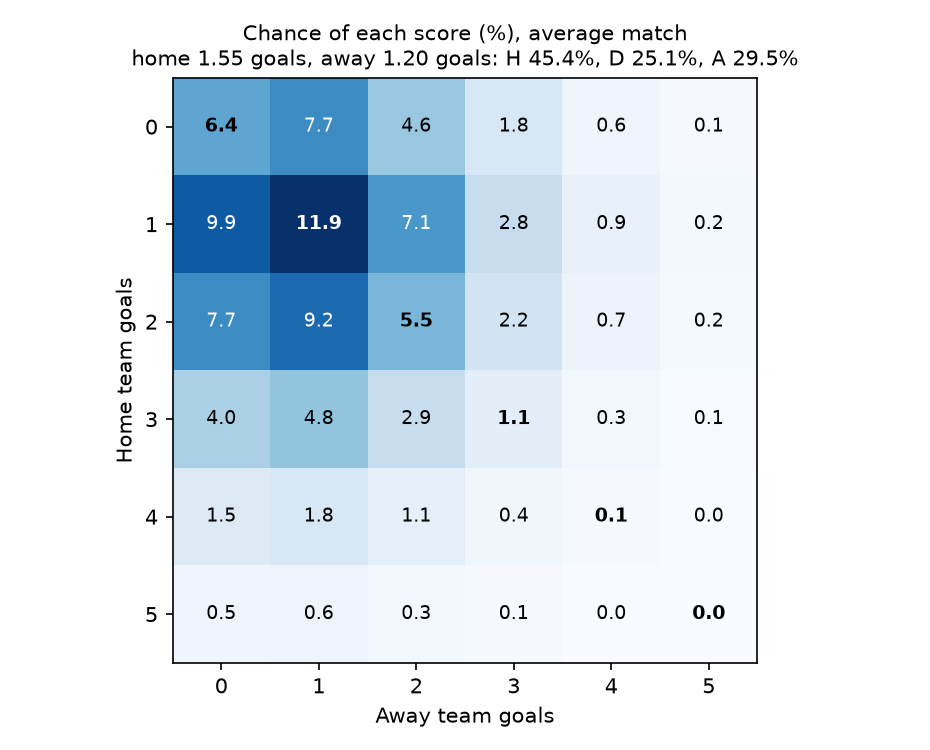

In [2]:
from IPython.display import Image, display
display(Image("ml_outputs/figures/poisson_scoreline_grid.png", width=430))

### 27.1 Reading the result
* **The idea works on an average match.** Using only the mean goals of the training seasons (home 1.55, away 1.20), the scoreline grid gives H 45.4%, D 25.1%, A 29.5%, against the actual 45.3%, 24.8% and 29.9%. Goal counts are close to Poisson: variance/mean is 1.11 for home goals and 1.13 for away goals (exactly Poisson would be 1.00).
* **Its probabilities are competitive.** Validation log loss 0.969, Brier score 0.576 and RPS 0.192 are slightly better than the class-weighted Random Forest (0.983, 0.587, 0.196) and close to the unweighted models of Section 15 (log loss 0.964 to 0.971).
* **It cannot recognise draws on its own.** The largest draw probability it gives any validation match is 0.292, so the most probable result is never a draw (Draw F1 0.000, Macro-F1 0.405). Two independent goal counts spread the chance of a draw thinly over 0-0, 1-1, 2-2 and so on, and the model also under-predicts draws on average (23.0% against 26.2% actual), the weakness Dixon and Coles (1997) addressed with a low-score adjustment.
* **The prior-corrected decision helps, but not enough.** It predicts a draw for 10.1% of matches (the Random Forest: 29.8%), reaching Draw F1 0.169 and Macro-F1 0.453, which is 0.039 below the Random Forest (paired bootstrap 95% CI −0.054 to −0.024). The decision rule is not met, so the Random Forest stays the final model.
* **What only a goal model gives:** expected goals for each team and a most likely exact score, which was correct for 13.2% of validation matches.

**Conclusion.** On the project's primary measure (Macro-F1) the Random Forest is clearly better; on probability quality the classic statistical model is as good or slightly better. This repeats the finding of Section 15: the right model depends on whether the user needs all three results recognised (Macro-F1) or the most accurate probabilities (log loss). Report Section 18.8 discusses this.